In [1]:
import os

import lifelines
import matplotlib.pyplot as plt
import matplotlib
import numpy
import pandas
import pickle
import time
import seaborn as sns

import immuw.clustering.clustering_utils as cimu
import tumorhood_analysis_utils as tau


# Number of enriched cellular neighborhood classes
CC_NB_OF_CLUSTERS = 23
ROI_TYPE_ANALYSIS = 'TLS'

CLUSTER_SELECTION_PATH = f'./NSCLC-Cello-v1-SD-100{CC_NB_OF_CLUSTERS}/'

VECTORIZER = lambda x: x.values.T ** 0.5
VECTORIZER_NAME = 'sqrt'
PANEL_1_CLUSTER_SELECTION_PATH = os.path.join(CLUSTER_SELECTION_PATH, f'p1_cs_result_{ROI_TYPE_ANALYSIS}_{VECTORIZER_NAME}.pickle')

# PREDICTION RELATED 
TYPE = 'sd'
PREDICTIONS_PATH = '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/nsclc_p1_sd_6ls/spatial_directions/clustering_results/0.75:13/kmeans_predictions/kmeans_predictions_23_1.npy'
PREDICTION_CLUSTER_COLUMN = 'Cellular Neighborhood'
CC_CLUSTER_NAME = 'tumorhood_neighborhood_cluster'

# IMAGE/SAMPLE RELATED 
ROI_COLUMN = 'image'
SAMPLE_COLUMN = 'sample_id'

CLINICAL_DATA_DF = 'nsclc_clinical_clean_corrected.csv'


PANEL_1_FULL_CSV_FILEPATH = '/raid/immucan/immuw/data/nsclc2_25_full.df'

# MARKER RELATED
MARKERS = tau.PANEL_1_MARKER_NAMES
MARKERS_CLEAN = [
    'MPO',
    'H3',
    'SMA',
    'CD16',
    'CD38',
    'HLA-DR',
    'CD27',
    'CD15',
    'CD45RA',
    'CD163',
    'B2M',
    'CD20',
    'CD68',
    'Ido1',
    'CD3',
    'LAG3',
    'CD11c',
    'PD1',
    'PDGFRb',
    'CD7',
    'GrB',
    'PDL1',
    'TCF7',
    'CD45RO',
    'FOXP3',
    'ICOS',
    'CD8a',
    'CAIX',
    'CD33',
    'Ki67',
    'VISTA',
    'CD40',
    'CD4',
    'CD14',
    'ECad',
    'CD303',
    'CD206',
    'cl.PARP',
    'DNA1',
    'DNA2',
]

# Clinical Related:
CLINICAL_DATA_COLS_FOR_ANALYSIS = [
    'roman_simple_stage', 
    'stage_2-',
    'simple_histology',
    #'neo_adjuvant_treatment',
    'death', 
    'smoking_status',
    'gender',
    #'environmental_exposure',
    'TPS_score',
    'CPS_score',
    'tmb_class',
    #'KRAS', 'TP53', 'EGFR', 'PIK3CA', 'ERBB2'
] 

# Additional Column names
DUMMY_COL_NAME = 'dummy'
CELLTYPE_COLNAME = 'celltypes'
CELLTYPE_PLOT_NAME = 'Cell type'
MARKER_PLOT_NAME = 'Marker'
ALL_PLOT_NAME = 'All'
ROI_CLUSTER_NAME = 'SG'

# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

matplotlib.font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'

## Cell type level data loading and preprocessing

In [2]:
cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)

/tmp/ipykernel_1213878/796832730.py:1: DtypeWarning: Columns (15,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)


In [3]:
# Marker ARCSINH x / 5 transformation
cell_df[MARKERS] =  cell_df[MARKERS].applymap(lambda x: numpy.arcsinh(x / 5.))

In [4]:
# Extra column for computations
cell_df[DUMMY_COL_NAME] = 1

## Prediction level loading

In [5]:
predictions = numpy.load(PREDICTIONS_PATH)

In [6]:
if TYPE == 'bag':
    cell_df[PREDICTION_CLUSTER_COLUMN] = cell_df[CC_CLUSTER_NAME].apply(lambda x: predictions[x])
elif TYPE == 'sd':
    cell_df[PREDICTION_CLUSTER_COLUMN] = predictions
else:
    raise ValueError('Unknown TYPE.')

## TLS / Tumor Core subselection

In [7]:
def roi_is_tls(image_name):
    return image_name[:-5].split('_')[-1] == '004'

In [8]:
TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: roi_is_tls(x))
NON_TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: not roi_is_tls(x))

In [9]:
if ROI_TYPE_ANALYSIS == 'Tumor':
    cell_df = cell_df[NON_TLS_CELL_SELECTOR]
elif ROI_TYPE_ANALYSIS == 'TLS':
    cell_df = cell_df[TLS_CELL_SELECTOR]
else:
    raise ValueError('Unknown ROI type analysis')

## Cell type related preparation:

In [10]:
celltype_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [11]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [12]:
celltypes = list(celltype_percentages.columns)

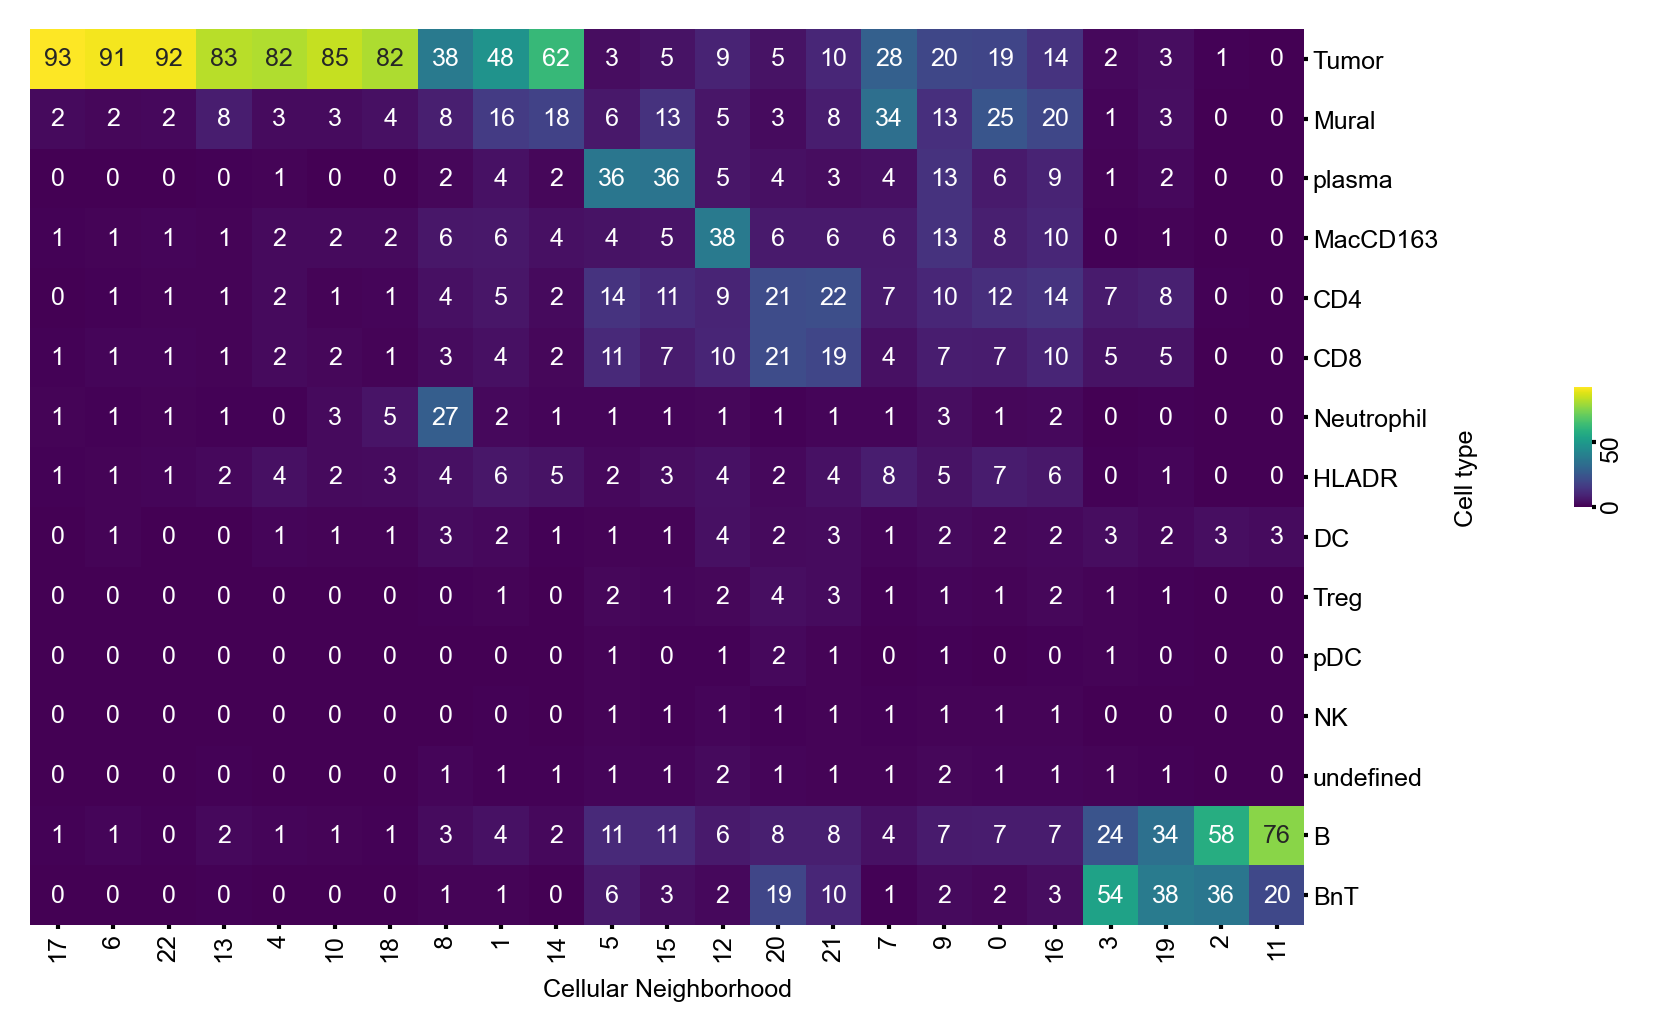

In [13]:
celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

#celltype_clustermap.ax_cbar.set_xlabel(f'{CELLTYPE_PLOT_NAME} percentage', labelpad=0, size=6)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
#celltype_clustermap.ax_row_colors.set_xticklabels(celltype_clustermap.ax_row_colors.get_xticklabels(), size=6)
#celltype_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [14]:
marker_to_celltype_dfs = {}


for marker in MARKERS:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [15]:
marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=MARKERS,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [16]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [17]:
all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = MARKERS_CLEAN

celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_1213878/762203048.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]


Now let's display the all marker distributions:

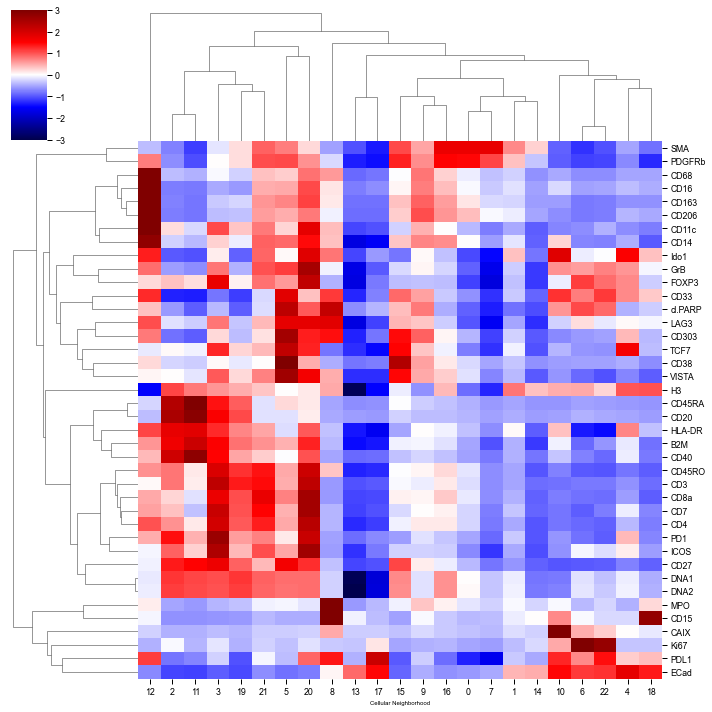

In [18]:
sns.clustermap(all_markers_distribution.T, center=0, cmap='seismic', vmin=-3, vmax=3)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [19]:
marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:

In [20]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

Now let's transform average markers across all cells to colors:

In [21]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:

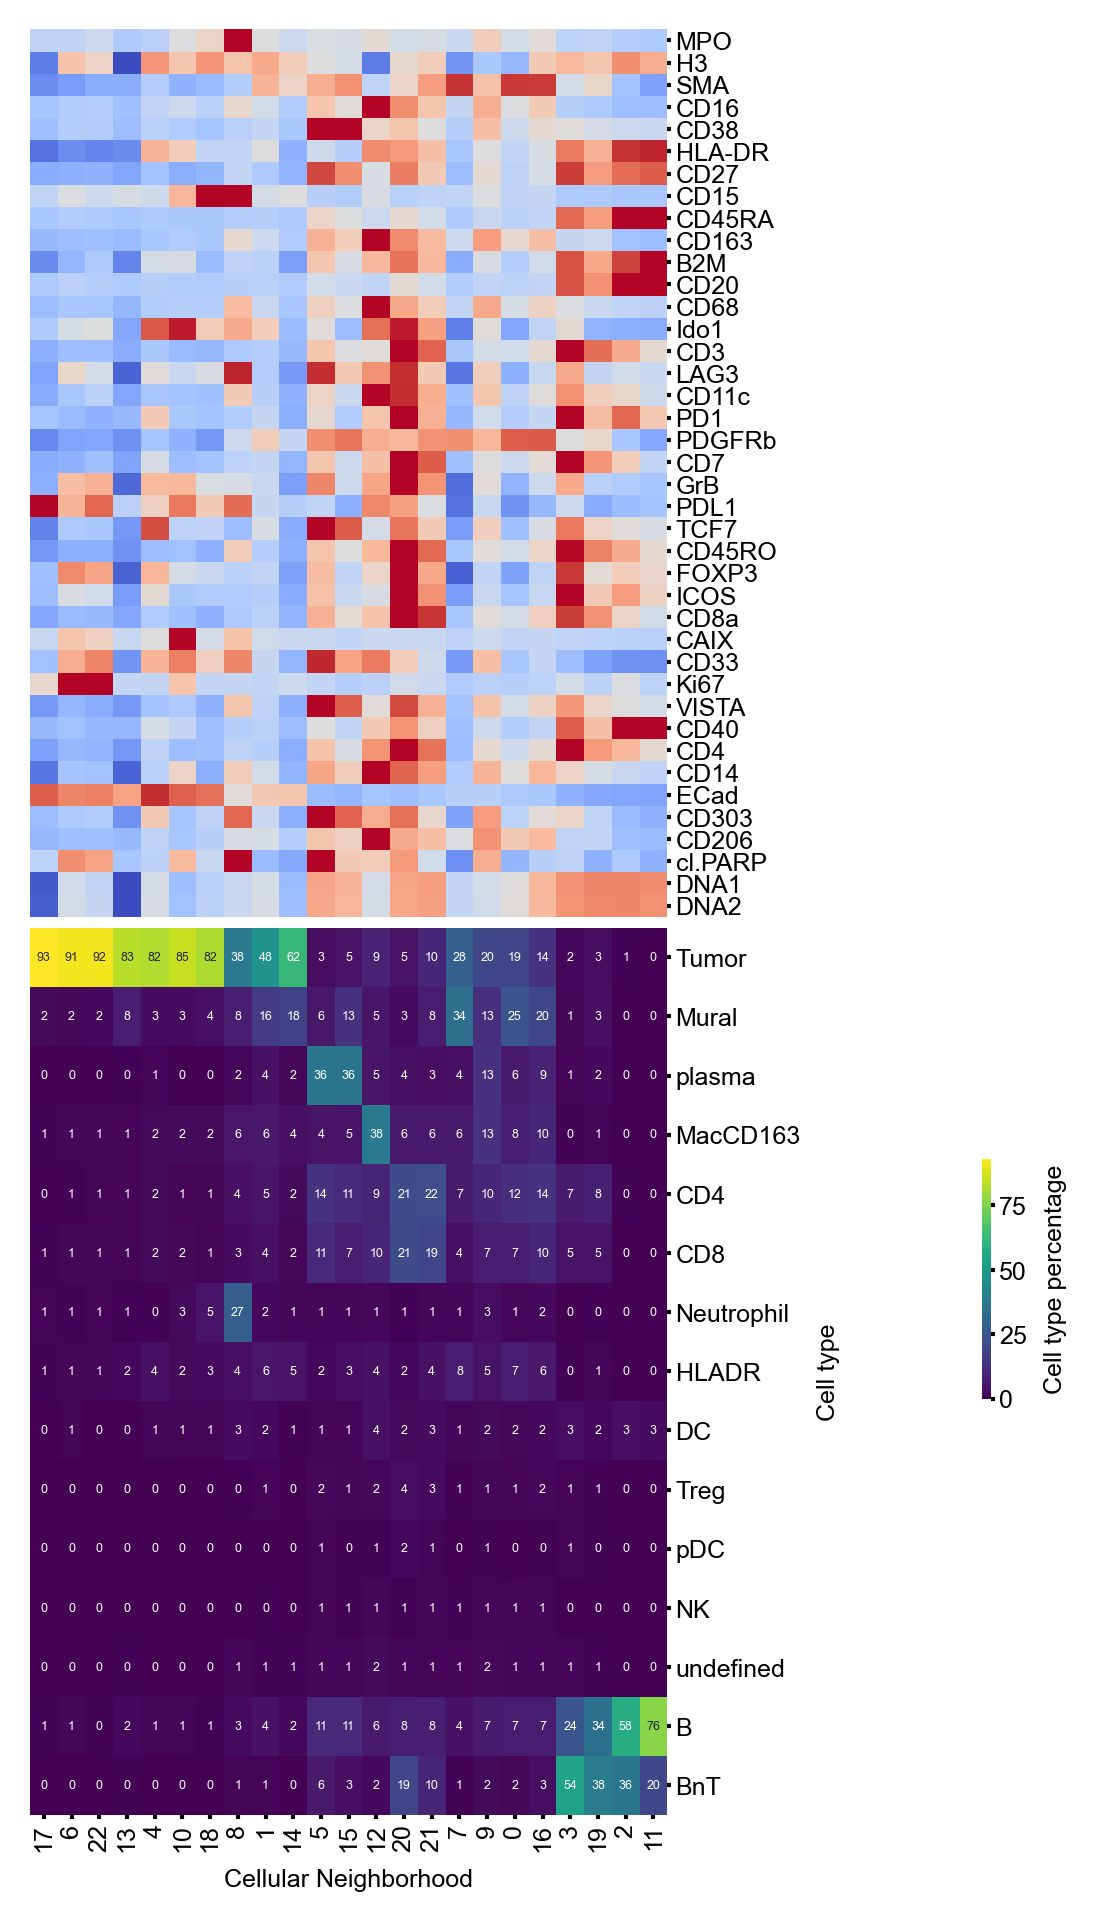

In [22]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

#celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
#    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
#)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))


## Density analysis

In [23]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

## ROI Based Analysis:

Let us start from collection of the roi counts:

In [24]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[ROI_COLUMN],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

Now, let's clinical data:

In [25]:
clinical_data_df = pandas.read_csv(CLINICAL_DATA_DF)
clinical_data_df['is_squamous'] = clinical_data_df['simple_histology'].apply(lambda x: 'squamous' in x.lower())

In [26]:
image_to_sample = cell_df.groupby(ROI_COLUMN)[SAMPLE_COLUMN].first()

In [27]:
roi_counts[ROI_COLUMN] = roi_counts.index

In [28]:
roi_counts['immucan_id'] = roi_counts['image'].apply(lambda x: image_to_sample[x])
roi_counts['immucan_id'] = roi_counts['immucan_id'].apply(
    lambda x: '-'.join(x.split('-')[:3])
)

In [29]:
roi_counts = pandas.merge(clinical_data_df, roi_counts, on='immucan_id')

In [30]:
roi_counts['patient'] = roi_counts['immucan_id']

## Core correlations analysis:

Let us start with obtaining general Cellohood cluster counts:

In [31]:
cluster_counts = cell_df.groupby(PREDICTION_CLUSTER_COLUMN).size()

Now - let's visualize Clusters correlations and counts:

/tmp/ipykernel_1213878/2560895134.py:47: UserWarning: FixedFormatter should only be used together with FixedLocator
  barplot_ax.set_xticklabels(


array([2.12, 2.12])

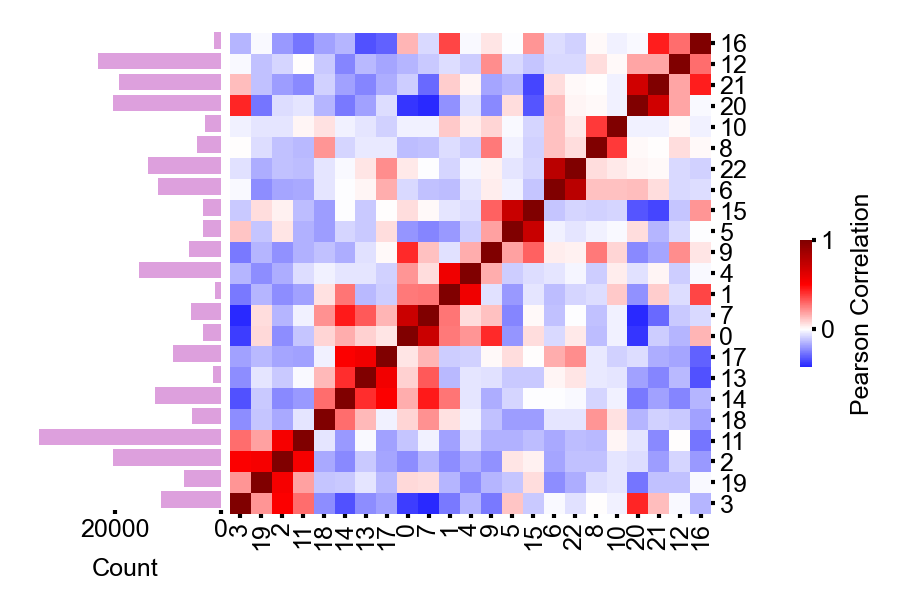

In [32]:
corr_df = roi_counts[list(range(CC_NB_OF_CLUSTERS))].corr()
#corr_df.index.name = 'Cellohood Neighborhood Cluster'
#corr_df.columns.name = 'Cellohood Neighborhood Cluster'

#matplotlib.rcParams.update(matplotlib.rcParamsDefault)

#sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
#plt.rcParams['legend.title_fontsize'] = 6
#plt.rcParams['legend.fontsize'] = 6
#matplotlib.rcParams['font.family'] = 'Arial'


corr_cmap = sns.clustermap(
    corr_df,
    center=0,
    cmap='seismic',
    xticklabels=True,
    yticklabels=True,
    #annot=True,
    #fmt='.2f',
    #annot_kws={'size': 3},
    cbar_pos=[1.1, 0.27, 0.02, 0.2],
    cbar_kws={'label': 'Pearson Correlation'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)
#corr_cmap.ax_cbar.set_visible(False)

barplot_ax = corr_cmap.fig.add_axes([-.11, 0.045, .3, .755], sharey=corr_cmap.ax_heatmap)
barplot_ax.barh(
    corr_cmap.data2d.columns + 0.5,
    cluster_counts[corr_cmap.data2d.columns],
    align='center',
    height=0.8,
    color='plum',
)
barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.yaxis.set_visible(False)
barplot_ax.set_xlabel('Count', size=6)
barplot_ax.xaxis.set_tick_params(size=1, left=True, pad=1)
barplot_ax.set_xticklabels(
    barplot_ax.get_xticklabels(), size=6, rotation=0
)
barplot_ax.set_facecolor('white')

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)
corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


# NOTE: full_cc_colors_with_ct is defined later in the notebook (out-of-order
# editing artifact); guard rather than fail here -- ticks keep default color.
try:
    for tick in corr_cmap.ax_heatmap.get_xticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])

    for tick in corr_cmap.ax_heatmap.get_yticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])
except NameError:
    pass

corr_cmap.fig.set_dpi(PLOTTING_DPI)
corr_cmap.fig.set_size_inches((2.12, 2.12))
plt.gcf().get_size_inches()

## Cluster number selection:

Let us run the algorithm for the cluster number selection:

In [33]:
PANEL_1_CLUSTER_SELECTION_PATH

'./NSCLC-Cello-v1-SD-10023/p1_cs_result_TLS_sqrt.pickle'

In [34]:
start_time = time.time()


if os.path.exists(PANEL_1_CLUSTER_SELECTION_PATH):
    with open(PANEL_1_CLUSTER_SELECTION_PATH, 'rb') as handle:
        cs_result = pickle.load(handle)
        cs_best_clusterers = cimu.get_best_clusters_from_cimu_result(cs_result)
else:
    cs_result, cs_best_clusterers = tau.perform_cluster_selection(
        cluster_counts, 
        list(range(CC_NB_OF_CLUSTERS)),
        vectorization_function=VECTORIZER,
        nb_of_tries_per_cluster_nb=10,
    )
    os.makedirs(CLUSTER_SELECTION_PATH, exist_ok=True)
    with open(PANEL_1_CLUSTER_SELECTION_PATH, 'wb') as handle:
        pickle.dump(panel_1_cs_result, handle)

print(time.time() - start_time)

0.007390260696411133


and let us have a look at found cluster numbers:

In [35]:
cs_best_clusterers

{16: MiniBatchKMeans(n_clusters=16, n_init='auto', random_state=173),
 22: MiniBatchKMeans(n_clusters=22, n_init='auto', random_state=237),
 25: MiniBatchKMeans(n_clusters=25, n_init='auto', random_state=269)}

## Patient Clustermap

In [36]:
ROI_CLUSTERS = 4
#clusterer = cs_best_clusterers[ROI_CLUSTERS]

/home/marmarmarmar/immucan/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


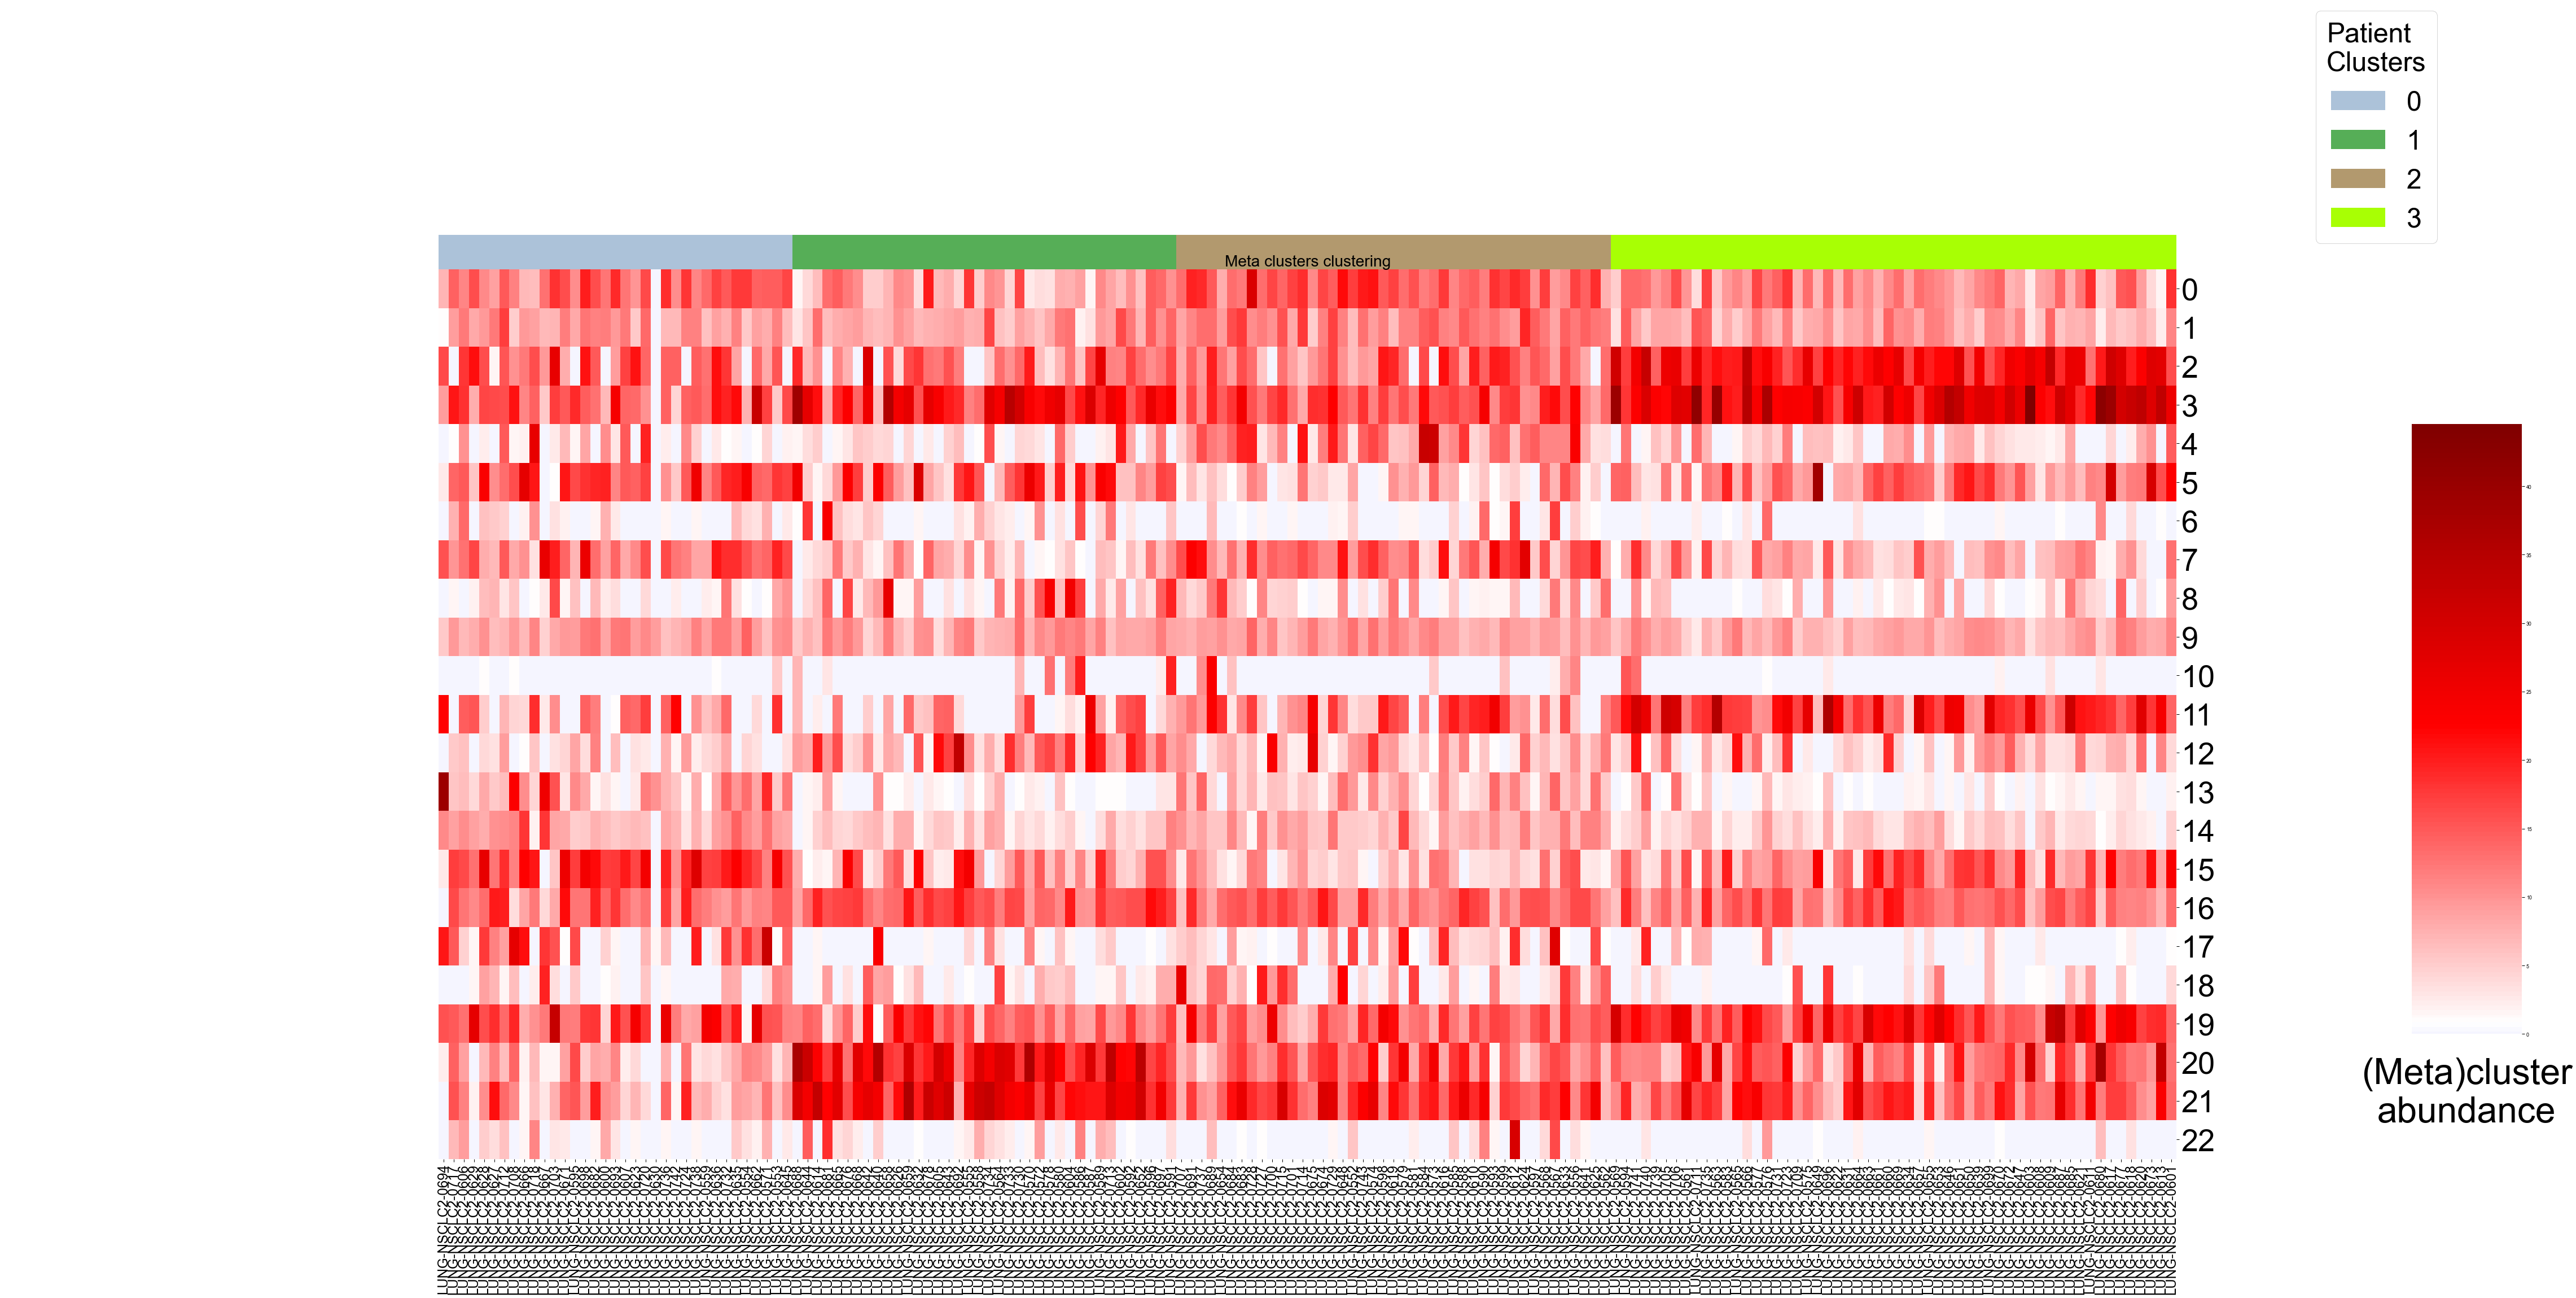

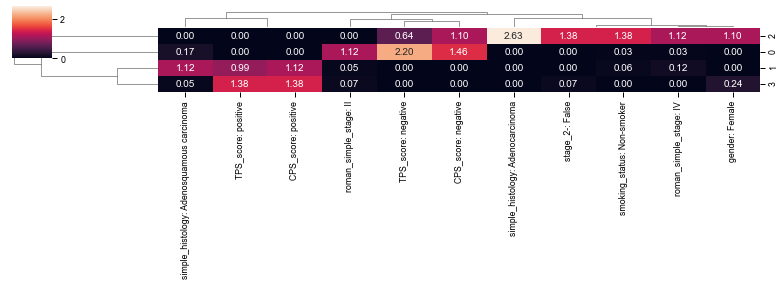

In [37]:
_, vectors, clusters, clusterer, qvals = tau.visualize_patient_clusters_with_survival_analysis_and_hg_no_lung(
    patients_df=roi_counts,
    clusterer_type='kmeans',
    clusters_to_select=list(range(CC_NB_OF_CLUSTERS)),
    hypergeometric_columns=CLINICAL_DATA_COLS_FOR_ANALYSIS,
    vectorization_function=VECTORIZER, 
    filter_below_percentage=0.01,
    cmap='seismic',
    number_of_clusters=ROI_CLUSTERS,
    hypergeometric_fdr_alpha=0.1,
    hypergeometric_filter_nas=True,
)

In [38]:
from collections import defaultdict

import matplotlib.colors as mpc


hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}


tmb_colors_dict = defaultdict(lambda: mpc.TABLEAU_COLORS['tab:cyan'])
tmb_colors_dict['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_colors_dict['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_colors_dict['<0.1'] = mpc.CSS4_COLORS['limegreen']

In [39]:
UNK_COLOR = mpc.CSS4_COLORS['lightgrey']

HISTOLOGY_PLOT_NAME = 'Histology'
STAGE_PLOT_NAME = 'Stage'
TMB_PLOT_NAME = 'TMB'
DEATH_PLOT_NAME = 'Death'
CPS_PLOT_NAME = 'CPS'
TPS_PLOT_NAME = 'TPS'
NEO_PLOT_NAME = 'Neo-adjuv.'

# Genes
KRAS_PLOT_NAME = 'GM: KRAS'
TP53_PLOT_NAME = 'GM: TP53'
EGFR_PLOT_NAME = 'GM: EGFR'
PIK3CA_PLOT_NAME = 'GM: PIK3CA'
ERBB2_PLOT_NAME = 'GM: ERBB2'

In [40]:
patient_to_clinical_colors_dict = {}

# Histology
patient_to_clinical_colors_dict[HISTOLOGY_PLOT_NAME] = [
    tau.SIMPLE_HISTOLOGY_COLORS[hist] for hist in roi_counts['simple_histology']
]

# Stage
patient_to_clinical_colors_dict[STAGE_PLOT_NAME] = [
    tau.SIMPLE_STAGE_COLORS[st] for st in roi_counts['simple_stage']
]

# TMB
tmb_color = defaultdict(lambda: UNK_COLOR)
tmb_color['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_color['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_color['<0.1'] = mpc.CSS4_COLORS['limegreen']
patient_to_clinical_colors_dict[TMB_PLOT_NAME] = [
    tmb_color[st] for st in roi_counts['tmb_class']
]

# Death
death_color = defaultdict(lambda: UNK_COLOR)
death_color[True] = mpc.CSS4_COLORS['red']
death_color[False] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[DEATH_PLOT_NAME] = [
    death_color[st] for st in roi_counts['death']
]

# CPS
cps_color = defaultdict(lambda: UNK_COLOR)
cps_color['positive'] = mpc.CSS4_COLORS['blue']
cps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[CPS_PLOT_NAME] = [
    cps_color[st] for st in roi_counts['CPS_score']
]

# TPS
tps_color = defaultdict(lambda: UNK_COLOR)
tps_color['positive'] = mpc.CSS4_COLORS['blue']
tps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[TPS_PLOT_NAME] = [
    tps_color[st] for st in roi_counts['TPS_score']
]

# Neoadjuvant therapy
neo_color = defaultdict(lambda: UNK_COLOR)
neo_color['Male'] = mpc.CSS4_COLORS['green']
neo_color['Female'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[NEO_PLOT_NAME] = [
    neo_color[st] for st in roi_counts['gender']
]

# GENES:
gene_color = defaultdict(lambda: UNK_COLOR)
gene_color[True] = mpc.CSS4_COLORS['white']
gene_color[False] = mpc.CSS4_COLORS['black']

# KRAS:
patient_to_clinical_colors_dict[KRAS_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['KRAS']
]

# TP53
patient_to_clinical_colors_dict[TP53_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['TP53']
]

#EGFR
patient_to_clinical_colors_dict[EGFR_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['EGFR']
]

# PIK3CA
patient_to_clinical_colors_dict[PIK3CA_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['PIK3CA']
]

# ERBB2
patient_to_clinical_colors_dict[ERBB2_PLOT_NAME] = [
    gene_color[st] for st in roi_counts['ERBB2']
]

patient_to_clinical_colors_df = pandas.DataFrame(patient_to_clinical_colors_dict)

In [41]:
centers = []
bars = [0]
aux = 0


for cl_ in range(ROI_CLUSTERS):
    current_cluster_count = (clusters == cl_).sum()
    centers.append(aux + current_cluster_count // 2)
    aux += current_cluster_count
    bars.append(aux - 1)

    
ticks = []
current_cluster = 0

for i in range(len(clusters)):
    if i in centers:
        ticks.append(current_cluster)
        current_cluster += 1
        continue
    elif i in bars:
        ticks.append('|')
        continue
    else:
        ticks.append('')
        

In [42]:
horizontal_ticks = [
    str(tick).replace('|', '-') 
    for tick in ticks
]

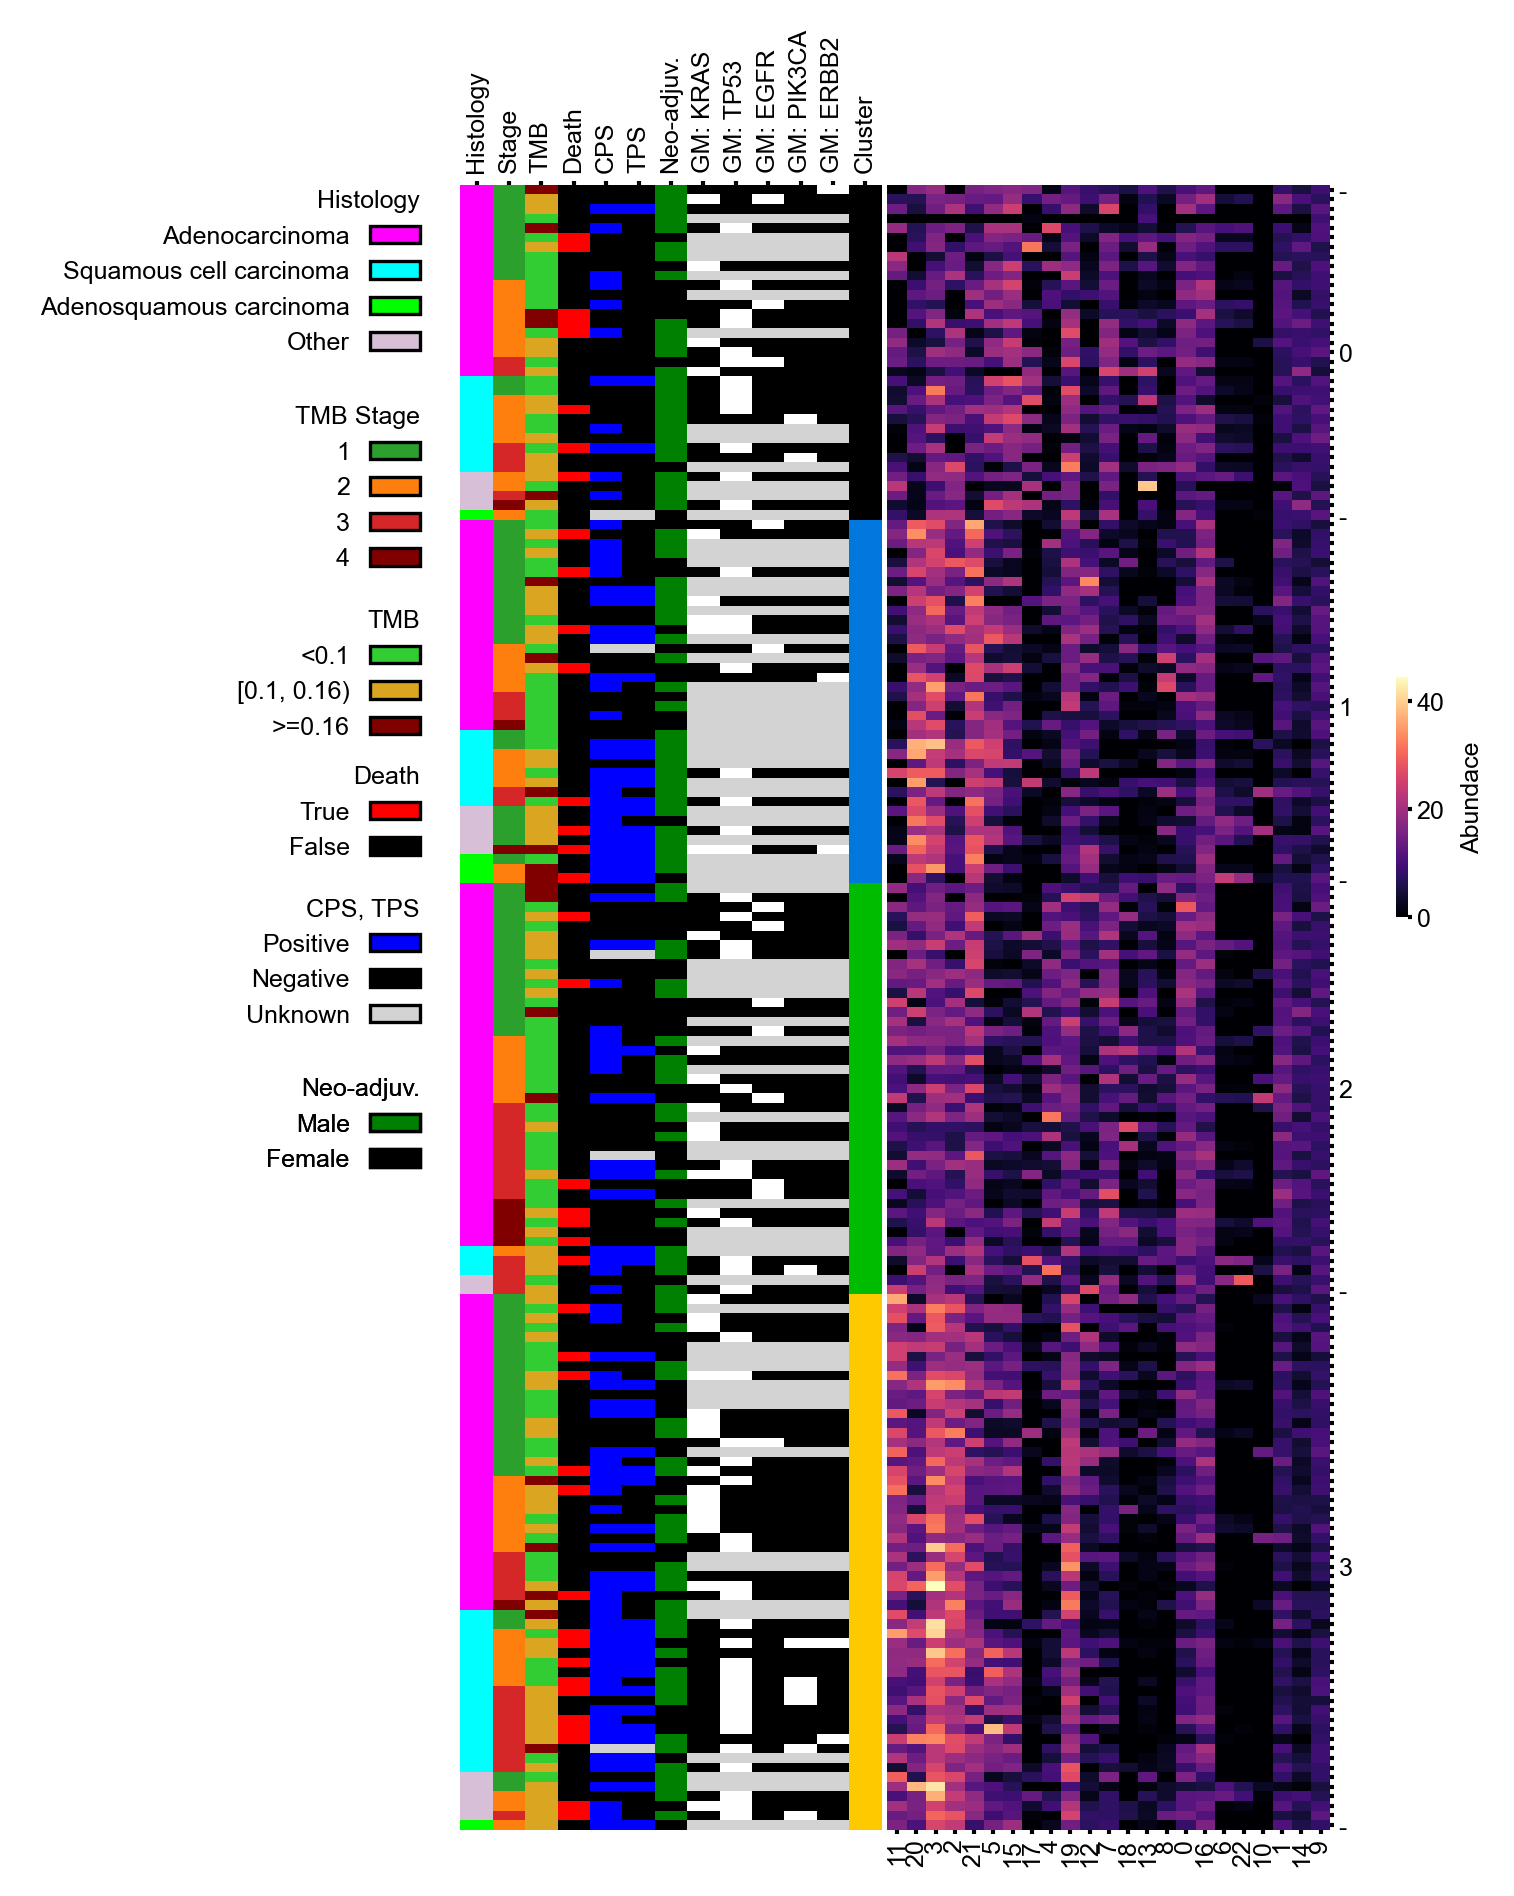

In [43]:
plt.rcParams['font.family'] = 'Arial'

cluster_norm = matplotlib.colors.Normalize(vmin=0, vmax=ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = matplotlib.cm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
#vectors_df.index.name = ROI_PLOT_NAME
#vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

BASE = 30

hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}

clusters_with_histology = clusters.copy()

for ind_, (cl, hist) in enumerate(zip(clusters_with_histology, roi_counts['simple_histology'])):
    clusters_with_histology[ind_] = BASE * cl + hist_to_int[hist]
    
for ind_, (cl, stage) in enumerate(zip(clusters_with_histology, roi_counts['simple_stage'])):
    clusters_with_histology[ind_] = BASE * cl + stage
    

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters_with_histology.argsort()].T.iloc[(-vectors_df.std(axis=0)).argsort()].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[.99, 0.5, 0.01, .1],
    cbar_kws={'label': 'Abundace'},
    yticklabels=horizontal_ticks,
    row_colors=patient_to_clinical_colors_df,
    figsize=(6, 8),
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
patient_clustermap.ax_row_colors.xaxis.tick_top()
#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

LEGEND_SPACING = 0.195

GOOD_HISTS = ['Adenocarcinoma', 'Squamous cell carcinoma', 'Adenosquamous carcinoma', 'Other']

pos_neg_handles = [
    matplotlib.patches.Patch(
        facecolor=tau.SIMPLE_HISTOLOGY_COLORS[name], 
        edgecolor='black') for name in GOOD_HISTS
]
pos_neg_legend = plt.legend(
    pos_neg_handles, 
    GOOD_HISTS, 
    title='Histology',
    bbox_to_anchor=(LEGEND_SPACING, .8125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(pos_neg_legend)

GOOD_STAGES = [1, 2, 3, 4]

grade_handles = [
    matplotlib.patches.Patch(facecolor=tau.SIMPLE_STAGE_COLORS[name], edgecolor='black') 
    for name in GOOD_STAGES
]
grade_legend = plt.legend(
    grade_handles, 
    GOOD_STAGES, 
    title='TMB Stage',
    bbox_to_anchor=(LEGEND_SPACING, .7225), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

GOOD_TMB = ['<0.1', '[0.1, 0.16)', '>=0.16']

tmb_handles = [
    matplotlib.patches.Patch(facecolor=tmb_color[name], edgecolor='black')
    for name in GOOD_TMB
]
tmb_legend = plt.legend(
    tmb_handles, 
    GOOD_TMB, 
    title='TMB',
    bbox_to_anchor=(LEGEND_SPACING, .6375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(tmb_legend)

death_handles = [
    matplotlib.patches.Patch(facecolor=death_color[name], edgecolor='black') 
    for name in death_color
]
death_legend = plt.legend(
    death_handles, 
    death_color, 
    title='Death',
    bbox_to_anchor=(LEGEND_SPACING, .5725), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(death_legend)

GOOD_TPSES = ['Positive', 'Negative', 'Unknown']

ps_handles = [
    matplotlib.patches.Patch(facecolor=tps_color[name], edgecolor='black')
    for name in tps_color
]
ps_legend = plt.legend(
    ps_handles, 
    GOOD_TPSES,
    title='CPS, TPS',
    bbox_to_anchor=(LEGEND_SPACING, .5175), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(ps_legend)

neo_handles = [
    matplotlib.patches.Patch(facecolor=neo_color[x], edgecolor='black')
    for x in neo_color
]
neo_legend = plt.legend(
    neo_handles, 
    neo_color, 
    title=f'{NEO_PLOT_NAME}',
    bbox_to_anchor=(LEGEND_SPACING, .4425), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(neo_legend)

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.fig.set_size_inches((4, 8))

In [44]:
from collections import defaultdict

import matplotlib.colors as mpc


hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}


tmb_colors_dict = defaultdict(lambda: mpc.TABLEAU_COLORS['tab:cyan'])
tmb_colors_dict['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_colors_dict['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_colors_dict['<0.1'] = mpc.CSS4_COLORS['limegreen']

In [45]:
UNK_COLOR = mpc.CSS4_COLORS['lightgrey']

HISTOLOGY_PLOT_NAME = 'Histology'
STAGE_PLOT_NAME = 'Stage'
TMB_PLOT_NAME = 'TMB'
DEATH_PLOT_NAME = 'Death'
CPS_PLOT_NAME = 'CPS'
TPS_PLOT_NAME = 'TPS'
GENDER_PLOT_NAME = 'Gender'
SMOKING_PLOT_NAME = 'Smoking'

# Genes
KRAS_PLOT_NAME = 'GM: KRAS'
TP53_PLOT_NAME = 'GM: TP53'
EGFR_PLOT_NAME = 'GM: EGFR'
PIK3CA_PLOT_NAME = 'GM: PIK3CA'
ERBB2_PLOT_NAME = 'GM: ERBB2'
ENV_EXP_NAME = 'Env.Exp.'

In [46]:
patient_to_clinical_colors_dict = {}

# Histology
patient_to_clinical_colors_dict[HISTOLOGY_PLOT_NAME] = [
    tau.SIMPLE_HISTOLOGY_COLORS[hist] for hist in roi_counts['simple_histology']
]

# Stage
patient_to_clinical_colors_dict[STAGE_PLOT_NAME] = [
    tau.SIMPLE_STAGE_COLORS[st] for st in roi_counts['simple_stage']
]

# TMB
tmb_color = defaultdict(lambda: UNK_COLOR)
tmb_color['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_color['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_color['<0.1'] = mpc.CSS4_COLORS['limegreen']
patient_to_clinical_colors_dict[TMB_PLOT_NAME] = [
    tmb_color[st] for st in roi_counts['tmb_class']
]

# Death
death_color = defaultdict(lambda: UNK_COLOR)
death_color[True] = mpc.CSS4_COLORS['red']
death_color[False] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[DEATH_PLOT_NAME] = [
    death_color[st] for st in roi_counts['death']
]

# CPS
cps_color = defaultdict(lambda: UNK_COLOR)
cps_color['positive'] = mpc.CSS4_COLORS['blue']
cps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[CPS_PLOT_NAME] = [
    cps_color[st] for st in roi_counts['CPS_score']
]

# TPS
tps_color = defaultdict(lambda: UNK_COLOR)
tps_color['positive'] = mpc.CSS4_COLORS['blue']
tps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[TPS_PLOT_NAME] = [
    tps_color[st] for st in roi_counts['TPS_score']
]

# gender therapy
neo_color = defaultdict(lambda: UNK_COLOR)
neo_color['Male'] = mpc.CSS4_COLORS['blue']
neo_color['Female'] = mpc.CSS4_COLORS['red']
patient_to_clinical_colors_dict[GENDER_PLOT_NAME] = [
    neo_color[st] for st in roi_counts['gender']
]

# # GENES:
# gene_color = defaultdict(lambda: UNK_COLOR)
# gene_color[True] = mpc.CSS4_COLORS['white']
# gene_color[False] = mpc.CSS4_COLORS['black']

# # KRAS:
# patient_to_clinical_colors_dict[KRAS_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['KRAS']
# ]

# # TP53
# patient_to_clinical_colors_dict[TP53_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['TP53']
# ]

# #EGFR
# patient_to_clinical_colors_dict[EGFR_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['EGFR']
# ]

# # PIK3CA
# patient_to_clinical_colors_dict[PIK3CA_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['PIK3CA']
# ]

# # ERBB2
# patient_to_clinical_colors_dict[ERBB2_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['ERBB2']
# ]

env_color = defaultdict(lambda: UNK_COLOR)
env_color['None'] = mpc.CSS4_COLORS['black']
env_color['Asbestos'] = mpc.CSS4_COLORS['yellowgreen']
env_color['Chemical agent'] = mpc.CSS4_COLORS['yellow']
env_color['Other'] = mpc.CSS4_COLORS['orange']

smoking_colors = {
    'Ex-smoker': '#d95f02',      # Orange
    'Current smoker': '#7570b3',  # Purple
    'Non-smoker': '#1b9e77'      # Green-blue
}


patient_to_clinical_colors_dict[SMOKING_PLOT_NAME] = [
    smoking_colors[x] for x in roi_counts['smoking_status']
]

# patient_to_clinical_colors_dict[ENV_EXP_NAME] = [
#     env_color[st] for st in roi_counts['environmental_exposure']
# ]

patient_to_clinical_colors_df = pandas.DataFrame(patient_to_clinical_colors_dict)

In [47]:
centers = []
bars = [0]
aux = 0


for cl_ in range(ROI_CLUSTERS):
    current_cluster_count = (clusters == cl_).sum()
    centers.append(aux + current_cluster_count // 2)
    aux += current_cluster_count
    bars.append(aux - 1)

    
ticks = []
current_cluster = 0

for i in range(len(clusters)):
    if i in centers:
        ticks.append(current_cluster)
        current_cluster += 1
        continue
    elif i in bars:
        ticks.append('|')
        continue
    else:
        ticks.append('')
        

In [48]:
horizontal_ticks = [
    str(tick).replace('|', '—') 
    for tick in ticks
]

In [49]:
PC_PLOT_COLS = ['Histology', 'Stage', 'TMB', 'Death', 'CPS', 'TPS', 'Gender', 'Smoking']

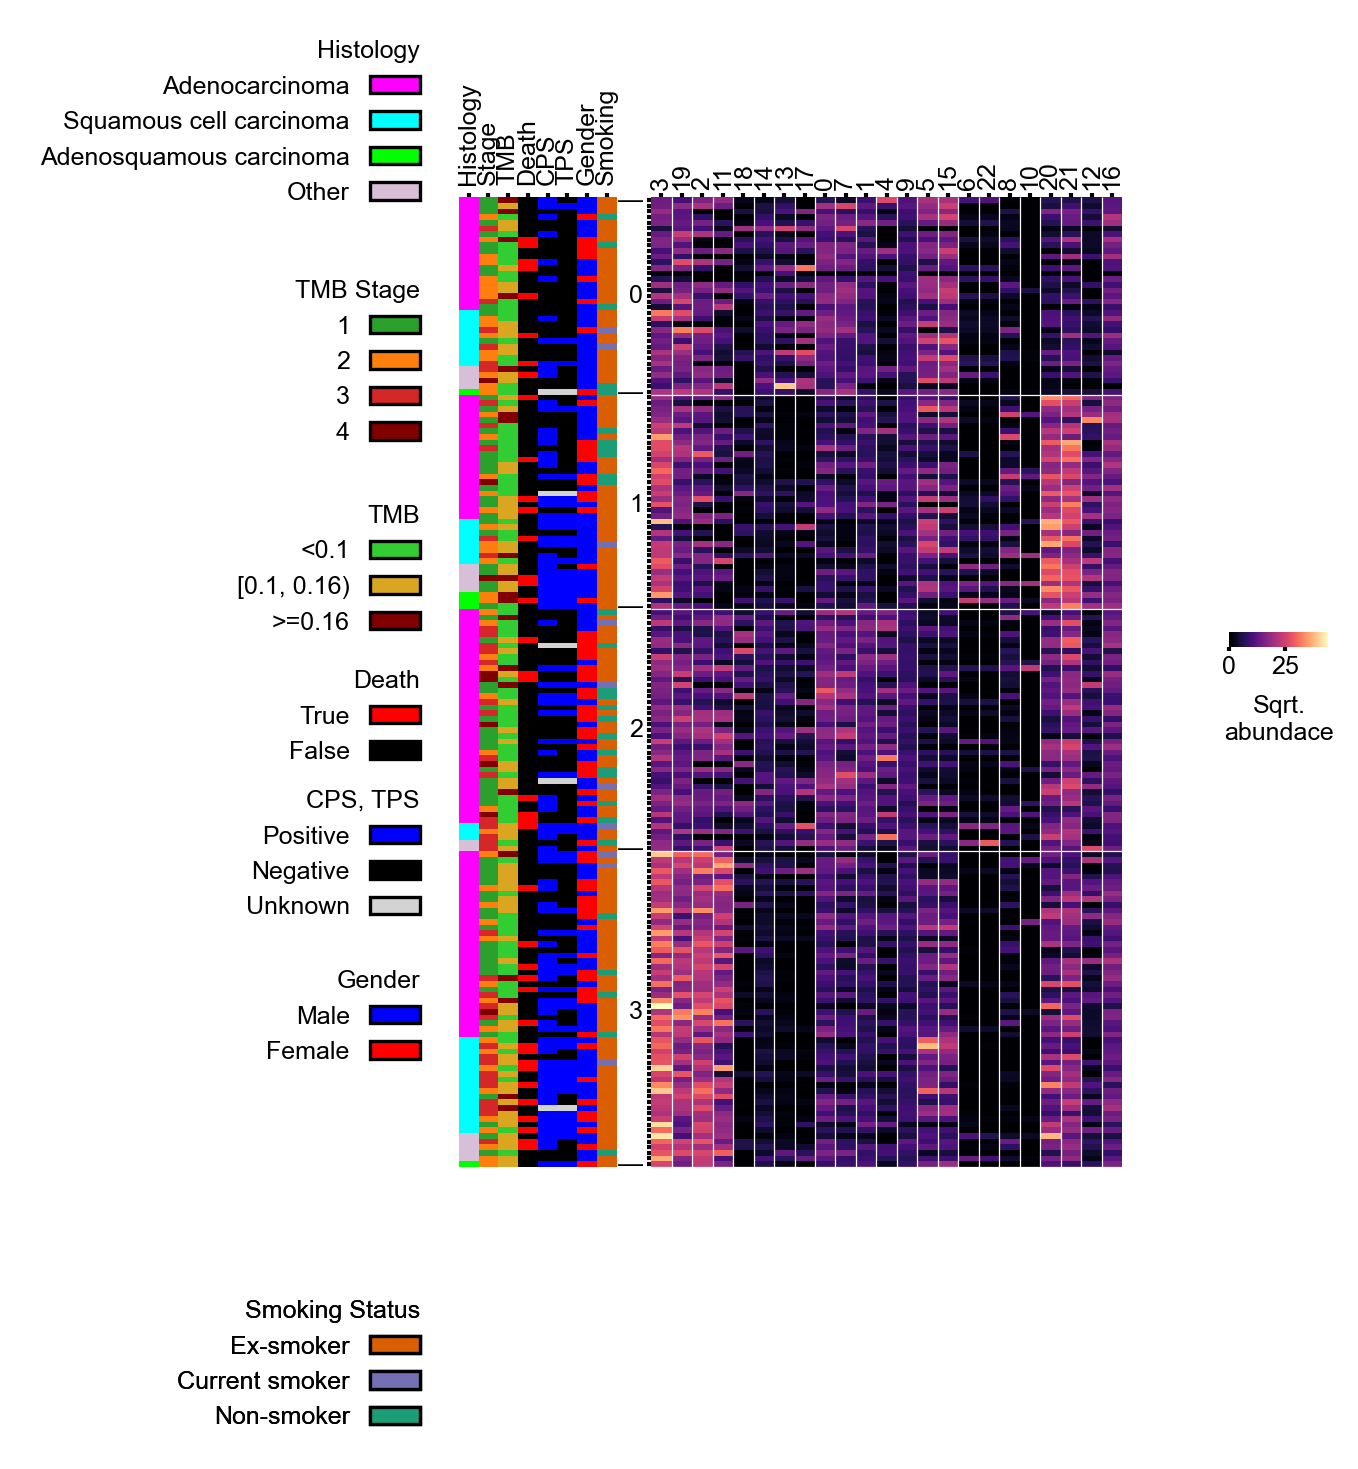

In [50]:
plt.rcParams['font.family'] = 'Arial'

cluster_norm = matplotlib.colors.Normalize(vmin=0, vmax=ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = matplotlib.cm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
#vectors_df.index.name = ROI_PLOT_NAME
#vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

BASE = 30

hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}

clusters_with_histology = clusters.copy()

for ind_, (cl, hist) in enumerate(zip(clusters_with_histology, roi_counts['simple_histology'])):
    clusters_with_histology[ind_] = BASE * cl + hist_to_int[hist]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters_with_histology.argsort()].T.iloc[corr_cmap.data2d.index].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[.99, 0.5, 0.1, .01],
    cbar_kws={'label': 'Sqrt.\nabundace', 'orientation': 'horizontal'},
    yticklabels=horizontal_ticks,
    colors_ratio=0.02507,
    row_colors=patient_to_clinical_colors_df[PC_PLOT_COLS],
    figsize=(3.3, 5),
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
patient_clustermap.ax_heatmap.xaxis.tick_top()

patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
patient_clustermap.ax_row_colors.xaxis.tick_top()

#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

LEGEND_SPACING = 0.195

GOOD_HISTS = ['Adenocarcinoma', 'Squamous cell carcinoma', 'Adenosquamous carcinoma', 'Other']

pos_neg_handles = [
    matplotlib.patches.Patch(
        facecolor=tau.SIMPLE_HISTOLOGY_COLORS[name], 
        edgecolor='black') for name in GOOD_HISTS
]
pos_neg_legend = plt.legend(
    pos_neg_handles, 
    GOOD_HISTS, 
    title='Histology',
    bbox_to_anchor=(LEGEND_SPACING, .92), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(pos_neg_legend)

GOOD_STAGES = [1, 2, 3, 4]

grade_handles = [
    matplotlib.patches.Patch(facecolor=tau.SIMPLE_STAGE_COLORS[name], edgecolor='black') 
    for name in GOOD_STAGES
]
grade_legend = plt.legend(
    grade_handles, 
    GOOD_STAGES, 
    title='TMB Stage',
    bbox_to_anchor=(LEGEND_SPACING, .76), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

GOOD_TMB = ['<0.1', '[0.1, 0.16)', '>=0.16']

tmb_handles = [
    matplotlib.patches.Patch(facecolor=tmb_color[name], edgecolor='black')
    for name in GOOD_TMB
]
tmb_legend = plt.legend(
    tmb_handles, 
    GOOD_TMB, 
    title='TMB',
    bbox_to_anchor=(LEGEND_SPACING, .61), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(tmb_legend)

death_handles = [
    matplotlib.patches.Patch(facecolor=death_color[name], edgecolor='black') 
    for name in death_color
]
death_legend = plt.legend(
    death_handles, 
    death_color, 
    title='Death',
    bbox_to_anchor=(LEGEND_SPACING, .5), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(death_legend)

GOOD_TPSES = ['Positive', 'Negative', 'Unknown']

ps_handles = [
    matplotlib.patches.Patch(facecolor=tps_color[name], edgecolor='black')
    for name in tps_color
]
ps_legend = plt.legend(
    ps_handles, 
    GOOD_TPSES,
    title='CPS, TPS',
    bbox_to_anchor=(LEGEND_SPACING, .42), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(ps_legend)

neo_handles = [
    matplotlib.patches.Patch(facecolor=neo_color[x], edgecolor='black')
    for x in neo_color
]
neo_legend = plt.legend(
    neo_handles, 
    neo_color, 
    title=f'{GENDER_PLOT_NAME}',
    bbox_to_anchor=(LEGEND_SPACING, .3), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(neo_legend)


# hg_handles = [
#     matplotlib.patches.Patch(facecolor=hg_colors[x], edgecolor='black')
#     for x in hg_colors
# ]
# hg_legend = plt.legend(
#     hg_handles, 
#     hg_colors, 
#     title='HG',
#     bbox_to_anchor=(LEGEND_SPACING, .2), 
#     bbox_transform=plt.gcf().transFigure,
#     frameon=False,
#     fontsize=6,
#     alignment='right',
#     markerfirst=False,
# )
# plt.gcf().add_artist(hg_legend)

sst_handles = [
    matplotlib.patches.Patch(facecolor=smoking_colors[x], edgecolor='black')
    for x in smoking_colors
]
sst_legend = plt.legend(
    sst_handles, 
    smoking_colors, 
    title='Smoking Status',
    bbox_to_anchor=(LEGEND_SPACING, .08), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(sst_legend)

# NOTE: full_cc_colors_with_ct is defined later in the notebook (out-of-order
# editing artifact); guard rather than fail here -- ticks keep default color.
try:
    for tick in patient_clustermap.ax_heatmap.get_xticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])
except NameError:
    pass

ax_row_colors = patient_clustermap.ax_row_colors
row_box = ax_row_colors.get_position()

box_heatmap = patient_clustermap.ax_heatmap.get_position()
ax_row_colors.set_position([box_heatmap.x0 - row_box.width - 0.035, row_box.y0, row_box.width, row_box.height])

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.ax_heatmap.yaxis.tick_left()
#patient_clustermap.fig.set_size_inches((4, 8))

for i in range(1, vectors_df.shape[1]):
    patient_clustermap.ax_heatmap.vlines(i, 0, vectors_df.shape[0], linewidth=0.3, color="white")

for bar in bars[1:]:
    patient_clustermap.ax_heatmap.hlines(bar + 1, 0, vectors_df.shape[1], linewidth=0.3, color="white")

## Clinical Data analysis

## Clinical Data analysis

In [51]:
roi_counts[DUMMY_COL_NAME] = 1
roi_counts[ROI_CLUSTER_NAME] = clusters

In [52]:
roi_cluster_counts = pandas.pivot_table(
    roi_counts, 
    values=DUMMY_COL_NAME, 
    index=['immucan_id'],
    columns=[ROI_CLUSTER_NAME],
    aggfunc="sum",
).fillna(0) > 0

In [53]:
roi_cluster_counts.shape

(172, 4)

In [54]:
ROI_CLUSTER_NAMES = [f'{ROI_CLUSTER_NAME}: {cl_}' for cl_ in roi_cluster_counts.columns]

ROI_CLUSTER_INDICES = list(roi_cluster_counts.columns)
roi_cluster_counts.columns = ROI_CLUSTER_NAMES
roi_cluster_counts.index.name = 'immucan_id'

In [55]:
roi_cluster_with_clinical = pandas.merge(roi_cluster_counts, clinical_data_df, on='immucan_id')

Now, let's filter out patients with percentage lower than `0.04`.

In [56]:
PERCENTAGE_TO_FILTER_OUT = 0.04

GOOD_ROI_CLUSTERS = [
    cl 
    for cl, row in roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows()
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]


GOOD_ROI_CLUSTERS_INDS = [
    row_nb 
    for row_nb, (cl, row) in enumerate(roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows())
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]

Now, let us compute a table with enrichements scores for clusters and clinical features, for subgroups of patients that have a particular ROI cluster:

In [57]:
import matplotlib.pyplot as plt


roi_pval_table = pandas.concat(
    [
        pandas.concat(
            [
                tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=roi_cluster_with_clinical[cluster] > 0,
                    column=column,
                    values=None,
                    filter_nas=True,
            ).iloc[[1]]
            for column in CLINICAL_DATA_COLS_FOR_ANALYSIS],
            axis=1,
        )
        for cluster in GOOD_ROI_CLUSTERS
    ],
    axis=0,
)

roi_pval_table.index = [
    f'{cluster}'
    for cluster in GOOD_ROI_CLUSTERS
]

Now, let's compute the FDR corrected p-values:

In [58]:
roi_qval_table = tau.apply_fdr_to_df(roi_pval_table)

Now, let's clean out the names of the clinical features:

In [59]:
raw_clinical_to_clean_clinical_names = {
    'smoking_status: ': '',
    '_score:': ':',
    'positive': 'Positive',
    'negative': 'Negative',
    'roman_simple_stage': 'TNB Stage',
    'simple_histology': 'Histology',
    'tmb_class': 'TMB',
    'stage_2-: False': 'TNB Stage: III, IV',
    'stage_2-: True': 'TNB Stage: I, II',
    'neo_adjuvant_treatment:': 'NeoAdj. Treat.:',
    'gender: ': '',
    'environmental_exposure': 'Env. Exposure',
    'Histology': 'Hist',
    'Adenosquamous carcinoma': 'Adeno-sq.',
    'KRAS': 'GM: KRAS',
    'PIK3CA': 'GM: PIK3CA',
    'EGFR': 'GM: EGFR',
    'TP53': 'GM: TP53',
    'ERBB2': 'GM: ERBB2',
    'death: 1': 'Death: True',
}

def clean_clinical_name(name, replacement_dict=None):
    if replacement_dict is None:
        replacement_dict = raw_clinical_to_clean_clinical_names
    for raw_name, clean_name in replacement_dict.items():
        name = name.replace(raw_name, clean_name)
    return name

In [60]:
roi_qval_table.columns = [clean_clinical_name(col) for col in roi_qval_table.columns]

Now, let's filter out the cases with `FDR_ALPHA` and lower scores:

In [61]:
FDR_ALPHA = 0.2

q_vals_sig_series = roi_qval_table.min() < FDR_ALPHA

sl_qvals_text = roi_qval_table.copy()
sl_qvals_text = sl_qvals_text.applymap(lambda x: str(round(x, 2)) if x < FDR_ALPHA  else '')

<Figure size 3600x2400 with 0 Axes>

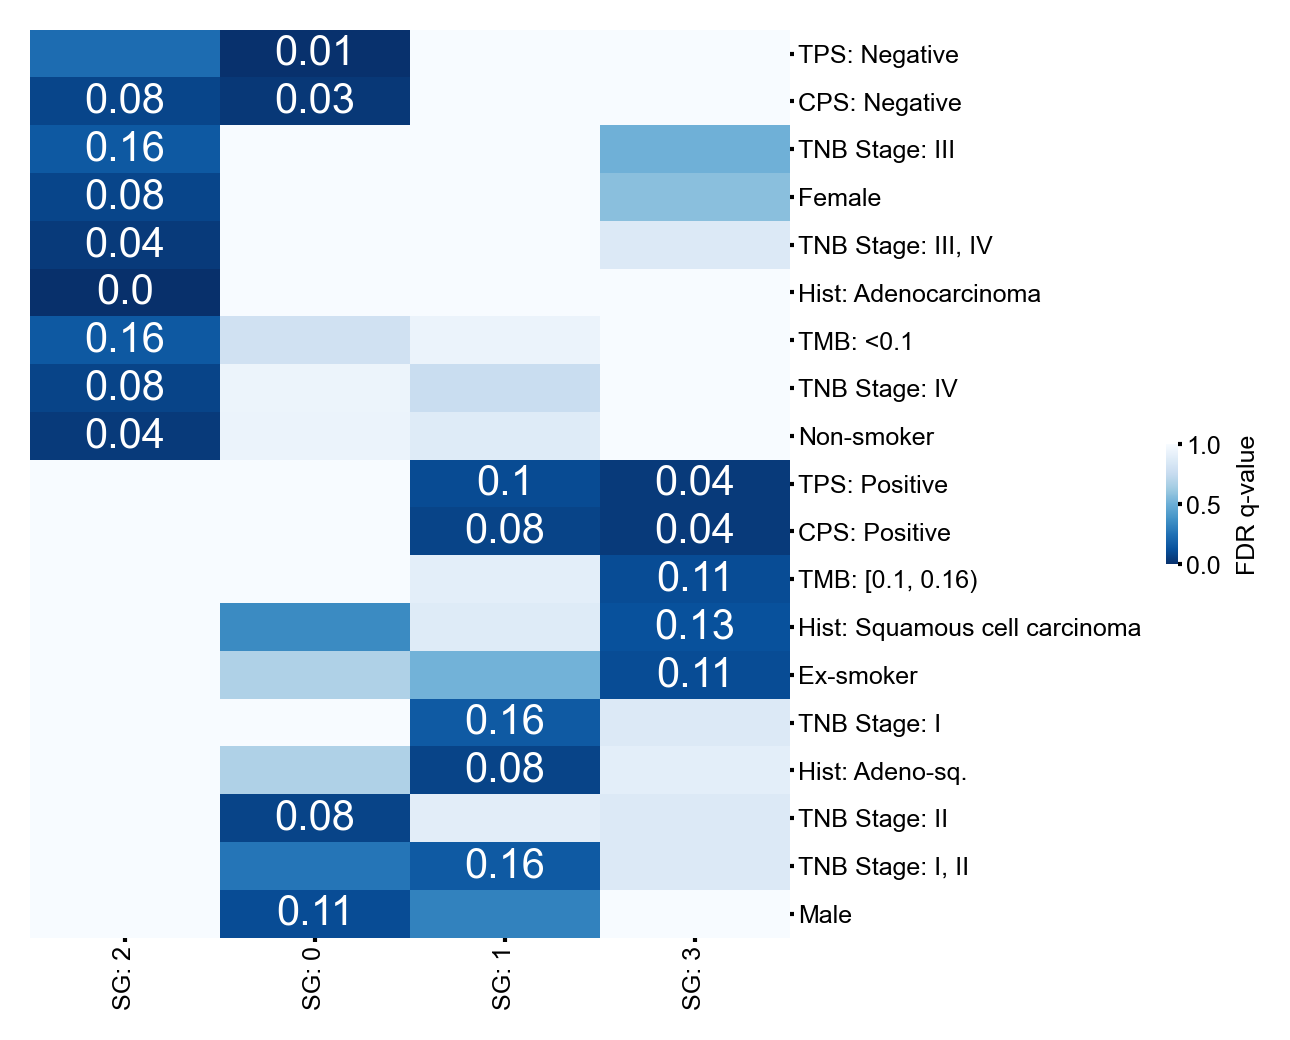

In [62]:
plt.figure(dpi=600)

clinical_cm = sns.clustermap(
    roi_qval_table.T[q_vals_sig_series], 
    cmap='Blues_r', 
    annot=sl_qvals_text.T[q_vals_sig_series], 
    yticklabels=sl_qvals_text.T[q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'FDR q-value'},
)
clinical_cm.ax_cbar.set_visible('False')
clinical_cm.ax_heatmap.xaxis.set_tick_params(rotation=0)

clinical_cm.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
clinical_cm.ax_row_dendrogram.set_visible(False)
clinical_cm.ax_col_dendrogram.set_visible(False)

clinical_cm.ax_heatmap.set_yticklabels(
    clinical_cm.ax_heatmap.get_yticklabels(), size=6
)
clinical_cm.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
clinical_cm.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
clinical_cm.ax_heatmap.set_xticklabels(
    clinical_cm.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

clinical_cm.fig.set_dpi(PLOTTING_DPI)
clinical_cm.fig.set_size_inches((4, 4))

## Histology Narrowed Clinical Analysis

Analysis within histologies:

<Figure size 3600x2400 with 0 Axes>

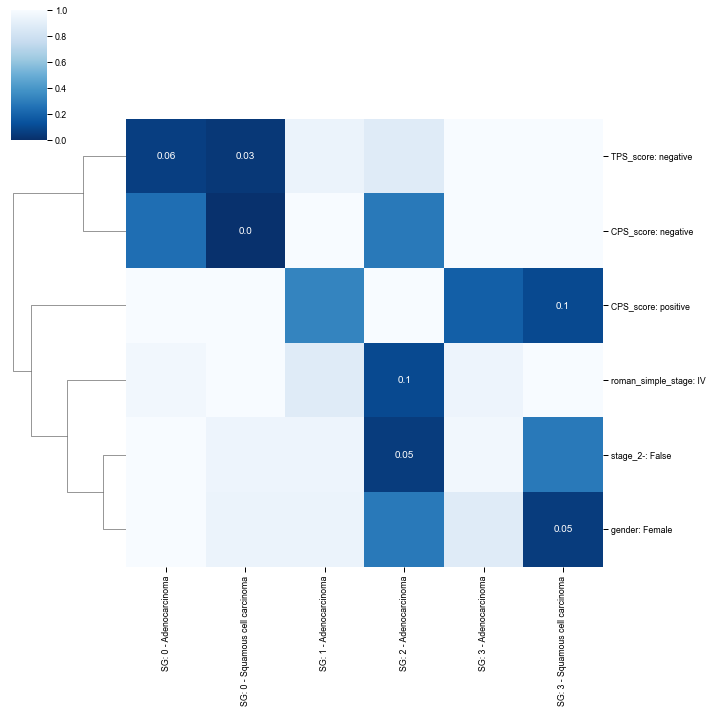

In [63]:
import matplotlib.pyplot as plt
from itertools import product


GROUP_SIZE_LIMIT = (roi_cluster_with_clinical['simple_stage'] == 4).sum()
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


dfs = []
indexes = []
for cluster, hist in product(GOOD_ROI_CLUSTERS, CLINICAL_TYPES):
    current_list = []
    hist_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_histology'] == hist] 
    current_clusters = hist_current_df[cluster] > 0
    if sum(current_clusters) < GROUP_SIZE_LIMIT:
        continue
    for column in CLINICAL_DATA_COLS_FOR_ANALYSIS:
        if column == 'simple_histology':
            continue
        current_df = tau.compute_hypergeometrics_for_df(
                    df=hist_current_df,
                    clusters=current_clusters,
                    column=column,
                    values=None,
            )
        if current_df.shape[0] > 1:
            current_list.append(current_df.iloc[[1]])
    if len(current_list) > 0:
        dfs.append(pandas.concat(current_list, axis=1))
        indexes.append(f'{cluster} - {hist}')
    

p1_pl_sl_hist_p_val_table = pandas.concat(dfs)
p1_pl_sl_hist_p_val_table.fillna(1., inplace=True)


p1_pl_sl_hist_p_val_table.index = indexes

p1_pl_sl_hist_qvals = tau.apply_fdr_to_df(p1_pl_sl_hist_p_val_table)

fdr_alpha = 0.1

p1_pl_hist_q_vals_sig_series = p1_pl_sl_hist_qvals.min() < fdr_alpha

p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals.copy()
p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals_text.applymap(lambda x: str(round(x, 2)) if x < fdr_alpha else '')

plt.figure(dpi=600)

in_hist_clinical_cm = sns.clustermap(
    p1_pl_sl_hist_qvals.sort_index().T[p1_pl_hist_q_vals_sig_series], 
    cmap='Blues_r', 
    col_cluster=False,
    annot=p1_pl_sl_hist_qvals_text.sort_index().T[p1_pl_hist_q_vals_sig_series], 
    yticklabels=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    #cbar=False,
    figsize=(10, 10),
)
#clinical_cm.ax_cbar.set_visible('False')

and within the whole dataset:

<Figure size 3600x2400 with 0 Axes>

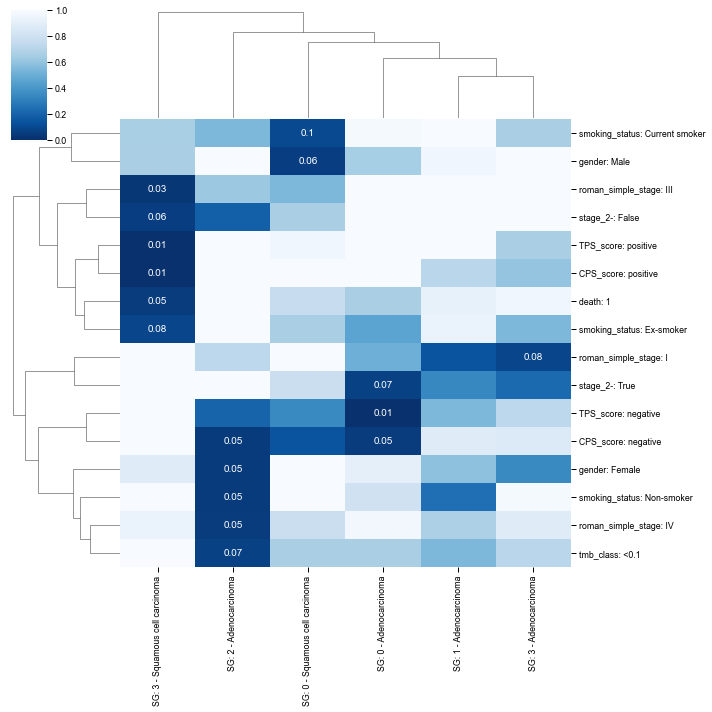

In [64]:
import matplotlib.pyplot as plt
from itertools import product


GROUP_SIZE_LIMIT = (roi_cluster_with_clinical['simple_stage'] == 4).sum()
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


dfs = []
indexes = []
for cluster, hist in product(GOOD_ROI_CLUSTERS, CLINICAL_TYPES):
    current_list = []
    current_clusters = (
        roi_cluster_with_clinical[cluster] > 0
    ) * (roi_cluster_with_clinical['simple_histology'] == hist)
    if sum(current_clusters) < GROUP_SIZE_LIMIT:
        continue
    for column in CLINICAL_DATA_COLS_FOR_ANALYSIS:
        if column == 'simple_histology':
            continue
        current_df = tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=current_clusters,
                    column=column,
                    values=None,
            )
        if current_df.shape[0] > 1:
            current_list.append(current_df.iloc[[1]])
    if len(current_list) > 0:
        dfs.append(pandas.concat(current_list, axis=1))
        indexes.append(f'{cluster} - {hist}')
    

p1_pl_sl_hist_p_val_table = pandas.concat(dfs)
p1_pl_sl_hist_p_val_table.fillna(1., inplace=True)


p1_pl_sl_hist_p_val_table.index = indexes

p1_pl_sl_hist_qvals = tau.apply_fdr_to_df(p1_pl_sl_hist_p_val_table)

fdr_alpha = 0.1

p1_pl_hist_q_vals_sig_series = p1_pl_sl_hist_qvals.min() < fdr_alpha

p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals.copy()
p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals_text.applymap(lambda x: str(round(x, 2)) if x < fdr_alpha else '')

plt.figure(dpi=600)

hist_clinical_cm = sns.clustermap(
    p1_pl_sl_hist_qvals.T[p1_pl_hist_q_vals_sig_series], 
    cmap='Blues_r', 
    annot=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series], 
    yticklabels=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    #cbar=False,
    figsize=(10, 10),
)
#clinical_cm.ax_cbar.set_visible('False')

Now, let's prepare a colored version of the above table:

In [65]:
clinical_norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
clinical_cmap = plt.get_cmap('Blues_r')

clinical_sm = matplotlib.cm.ScalarMappable(norm=clinical_norm, cmap=clinical_cmap)

clinical_colors = clinical_cm.data2d.applymap(lambda x: clinical_sm.to_rgba(x))

In [66]:
clinical_cm.data2d.to_csv('plda_75_tls_q.csv')

## Survival analysis:

Now, let's prepare a table for the Cox analysis. We will use the information about grades and clinical types, similarly to the original paper.

### CC Cluster analysis:

Now, let's prepare the main Cox table for the Cellohood cluster sqrt counts:

In [67]:
additional_feature_columns=('is_adeno', 'is_squamous',)# 'Gender_male', 'Smoking', 'Smoking-Non', 'Smoking-Ex')

STD_EPS = 2

jackson_survival_df_clusters = pandas.DataFrame(
    {
        **{
            'died': roi_counts[tau.DEATH_COLNAME],
            'survival': roi_counts[tau.SURVIVAL_COLNAME], 
            'simple_stage': roi_counts[tau.SIMPLE_STAGE_COLNAME],
        },
       **{
            col: roi_counts[col]
            for col in additional_feature_columns
        },
        **{
            f'simple_stage_{i}': (roi_counts[tau.SIMPLE_STAGE_COLNAME] == i).astype('int')
            for i in range(1, 4 + 1) if sum(roi_counts[tau.SIMPLE_STAGE_COLNAME] == i)
        },
        **{
            f'pl_{i}': roi_counts[i] ** 0.5 
            for i in range(CC_NB_OF_CLUSTERS)
            if (roi_counts[i] ** 0.5).std() > STD_EPS
        },
    }
)

Now, let's run the Cox model:

In [68]:
def rename_cox_summary_index(index_, prefix='ROI', simple_stage_name='Grade'):
    new_index = []
    for el in index_:
        if el.startswith('pl'):
            new_index.append(f'{prefix}: {el.split("_")[-1]}')
            continue
        if el.startswith('simple_stage'):
            new_index.append(f'{simple_stage_name}: {el.split("_")[-1]}')
            continue
        new_index.append(el)
    return new_index
        

/tmp/ipykernel_1213878/4228937197.py:29: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)


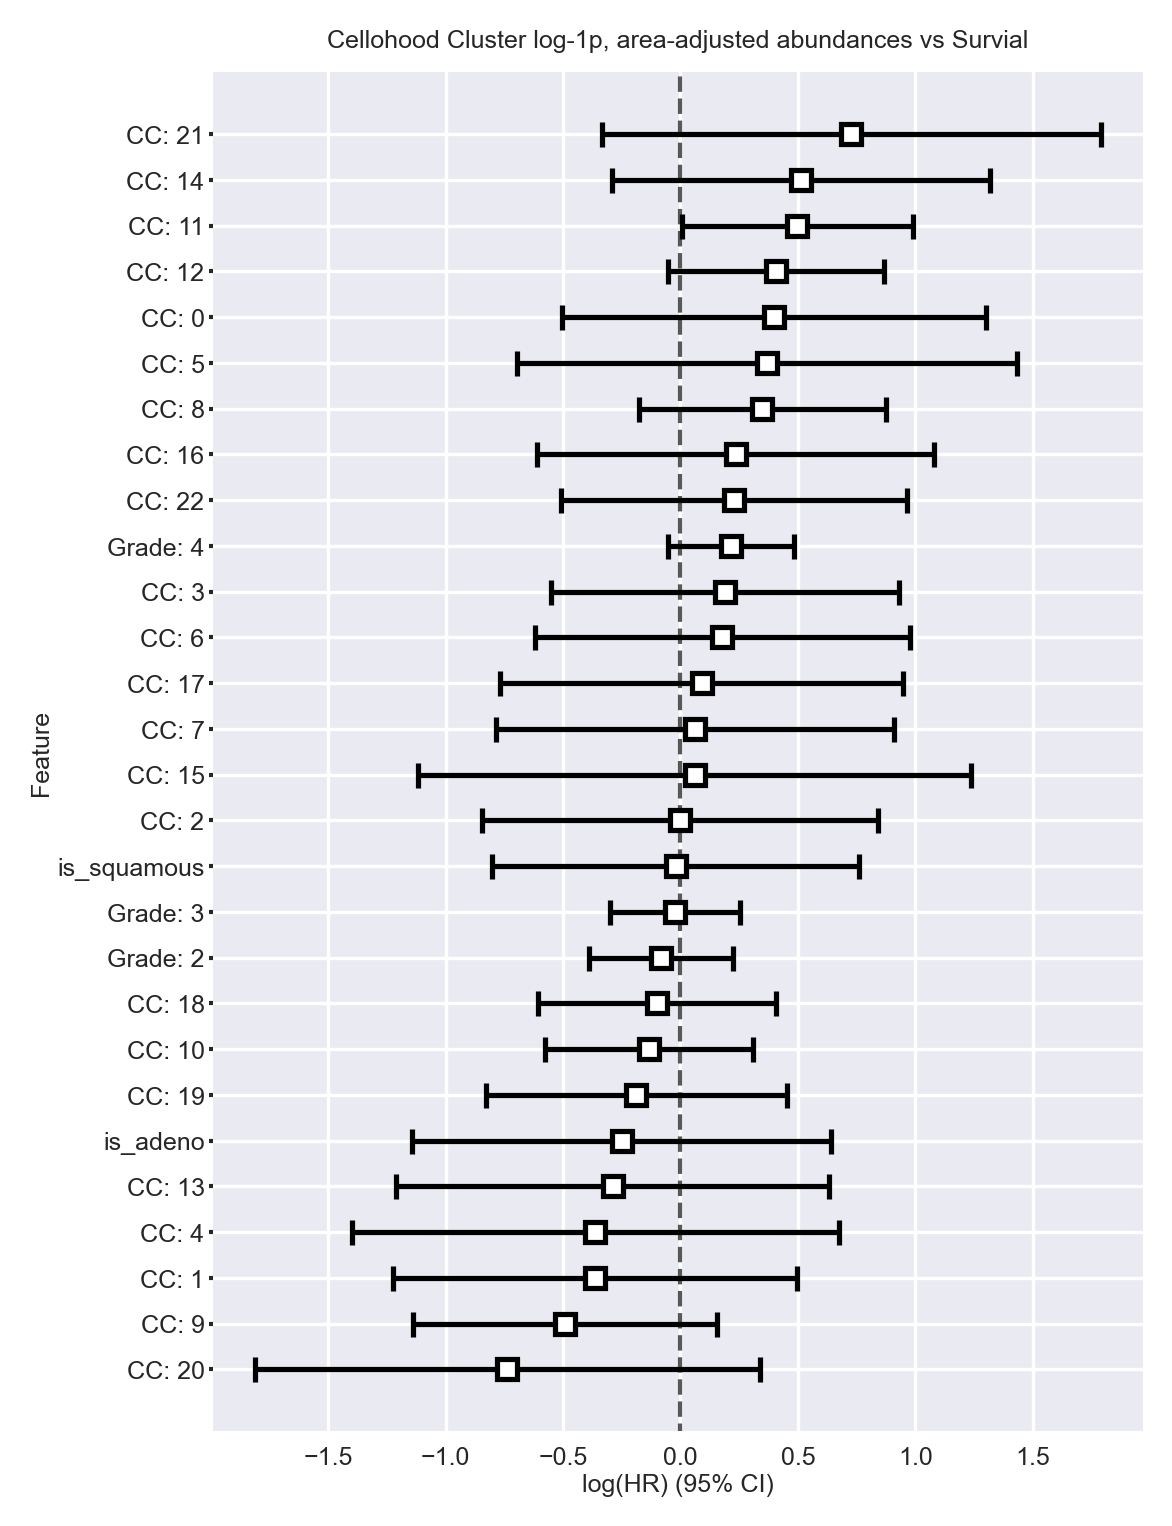

In [69]:
l2_true_value = 1e-3
l1_true_value = 0

coxphf_penalizer = l1_true_value + l2_true_value
coxphf_l1 = l1_true_value / (l1_true_value + l2_true_value)


jackson_cluster_cox = tau.surivial_on_df(
    jackson_survival_df_clusters, 
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer, 
    standardize=True,
    #cox_kwargs={'step_size': 0.1},
    fit_kwargs={
        'robust': True, 
        'strata': 'simple_stage_1', 
    }
)
plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(4, 6), dpi=300)
jackson_cluster_cox.plot()
plt.title('Cellohood Cluster log-1p, area-adjusted abundances vs Survial', size=6)
cox_ax = plt.gca()
yticklabels = [el.get_text() for el in cox_ax.get_yticklabels()]
_ = cox_ax.set_yticklabels(rename_cox_summary_index(yticklabels, prefix='CC'), size=6)
plt.ylabel('Feature', labelpad=1, fontdict={'size': 6})
plt.xlabel('log(HR) (95% CI)', labelpad=1, fontdict={'size': 6})
cox_ax.yaxis.set_tick_params(pad=1, size=1)
_ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)

### ROI Cluster Analysis

In [70]:
survival_df = pandas.DataFrame(
       {
            **{
                'died': roi_cluster_with_clinical[tau.DEATH_COLNAME],
                'survival': roi_cluster_with_clinical[tau.SURVIVAL_COLNAME], 
                'simple_stage': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME],
            },
           **{
               col: roi_cluster_with_clinical[col]
               for col in additional_feature_columns
           },
            **{
                f'simple_stage_{i}': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i
                for i in range(1, 4 + 1) if sum(roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i)
            },
            **{
                f'pl_{ROI_CLUSTERS}_{int(i)}': roi_cluster_with_clinical[f'SG: {i}']
                for i in GOOD_ROI_CLUSTERS_INDS
            },
        }
    )

In [71]:
def get_cox_feature_colors(
    feature,
    cluster_prefix='ROI: '
):
    if feature.startswith(cluster_prefix):
        cluster_ind = int(feature.split(cluster_prefix)[-1])
        return cluster_sm.to_rgba(cluster_ind)
    if feature.startswith('HR'):
        return clinical_type_color[feature]
    if feature.startswith('Grade'):
        grade_int = int(feature[-1])
        return grade_color[grade_int]

/tmp/ipykernel_1213878/1771896420.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = ax.set_xticklabels(ax.get_xticklabels(), size=6)


Text(0.5, 1.0, 'Cox PH Model\nfor ROI Clusters')

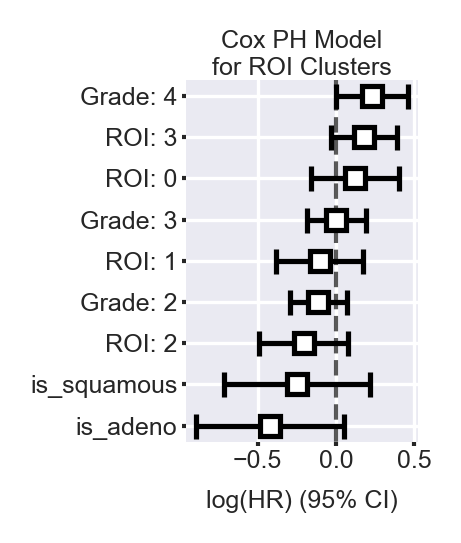

In [72]:
jackson_cox = tau.surivial_on_df(
    survival_df,
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer,
    fit_kwargs={'robust': True, 'strata': 'simple_stage_1'},
)

plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(1., 1.6), dpi=300)
ax = jackson_cox.plot()
yticklabels = [el.get_text() for el in ax.get_yticklabels()]
new_labels = rename_cox_summary_index(yticklabels)
_ = ax.set_yticklabels(new_labels, size=6)
#for ticklabel, tickcolor in zip(ax.get_yticklabels(), labels_colors):
#    ticklabel.set_color(tickcolor)
ax.yaxis.set_tick_params(pad=1, size=1)
_ = ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.xaxis.set_tick_params(pad=1, size=1)
#ax.set_ylabel('Feature')
ax.set_title('Cox PH Model\nfor ROI Clusters', fontsize=6, pad=1)
#ax.get_children()[0].set_color('blue')

In [73]:
DATA_COX_COLS = ['died', 'survival', 'simple_stage', 'is_adeno', 'simple_stage_1',
       'simple_stage_2', 'simple_stage_3', 'simple_stage_4']


for roi in GOOD_ROI_CLUSTERS_INDS:
    current_cluster_colname = f'pl_{ROI_CLUSTERS}_{int(roi)}'
    current_cox_cols = DATA_COX_COLS + [current_cluster_colname]
    current_cox = tau.surivial_on_df(
        survival_df[current_cox_cols], 
        l1_ratio=coxphf_l1, 
        penalizer=coxphf_penalizer,
        fit_kwargs={'robust': False, 'strata': 'simple_stage_1'},
    )
    if current_cox.summary.loc[current_cluster_colname]['coef lower 95%'] * current_cox.summary.loc[current_cluster_colname]['coef upper 95%'] > 0:
        plt.figure(figsize=(10, 10))
        current_cox.plot()
        plt.title(roi)

## Kaplan-Meier Curves:

### Cross-ROI clusters analysis

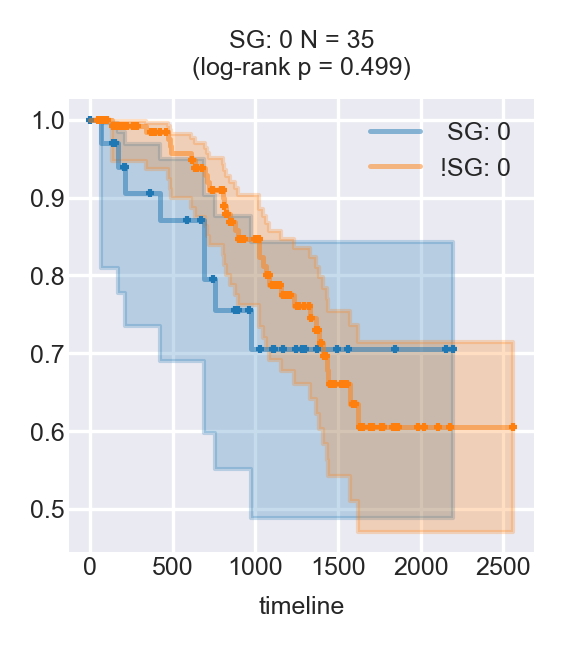

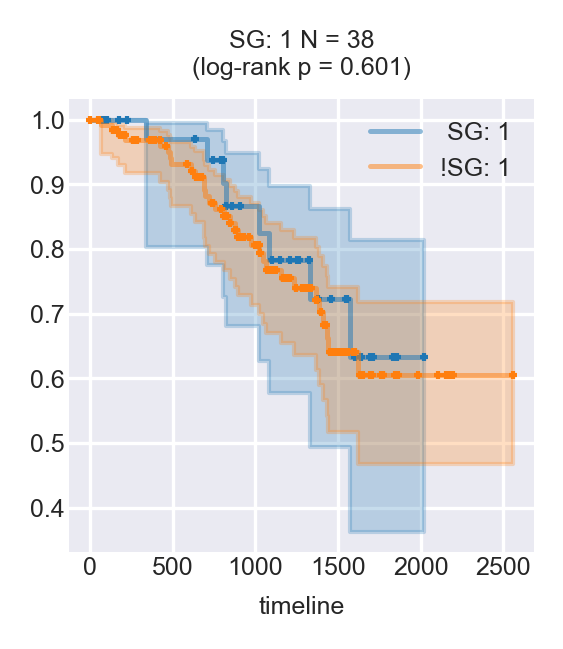

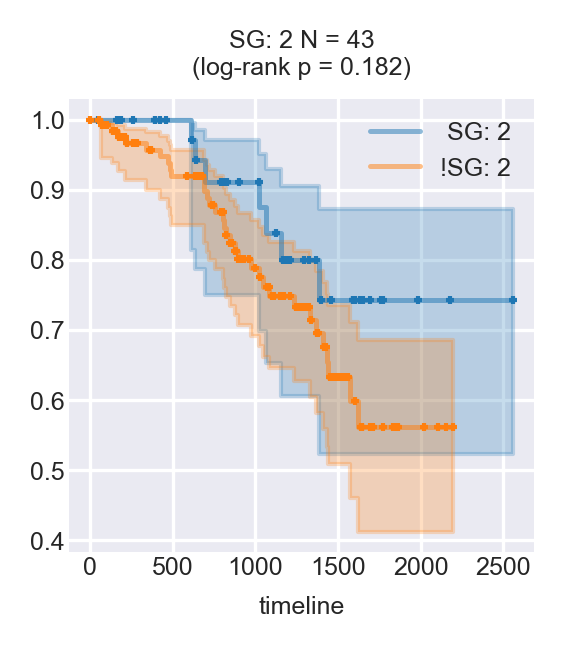

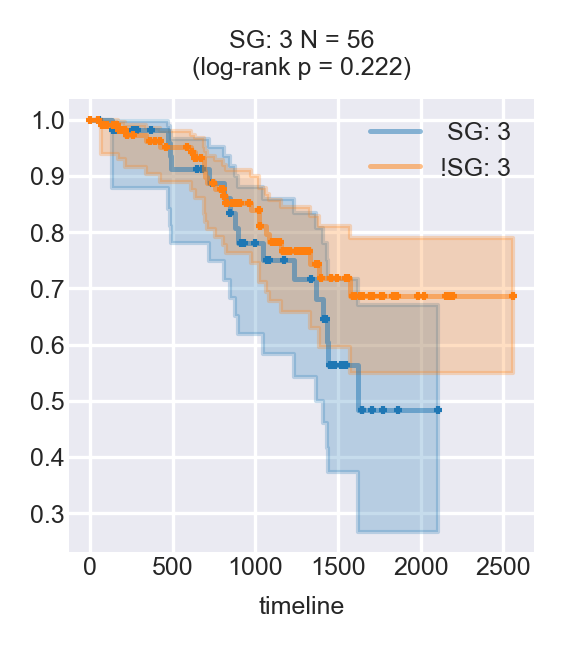

In [74]:
cluster_log_rank_p_values = numpy.ones((len(GOOD_ROI_CLUSTERS), 1))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        if l_N < 15:
            print(l_N)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cluster_log_rank_p_values[l_ind, 0] = current_test.p_value
        if cluster_log_rank_p_values[l_ind, 0] < 0.95:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f' {l_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'!{l_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} N = {l_current_df.shape[0]}\n(log-rank p = {round(cluster_log_rank_p_values[l_ind, 0], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

In [75]:
l_current_df = roi_cluster_with_clinical[numpy.logical_or(roi_cluster_with_clinical['SG: 0'], roi_cluster_with_clinical['SG: 2'])]
l_current_df = roi_cluster_with_clinical[numpy.logical_or(roi_cluster_with_clinical['SG: 1'], roi_cluster_with_clinical['SG: 3'])]
l_N = l_current_df.shape[0]
current_test = lifelines.statistics.logrank_test(
    l_current_df['days_to_death'], r_current_df['days_to_death'],
    l_current_df['death'], r_current_df['death'],
)

In [76]:
current_test

<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           0.69 0.41      1.30

In [77]:
cluster_log_rank_p_values_df = pandas.DataFrame(
    cluster_log_rank_p_values,
    index=GOOD_ROI_CLUSTERS,
)

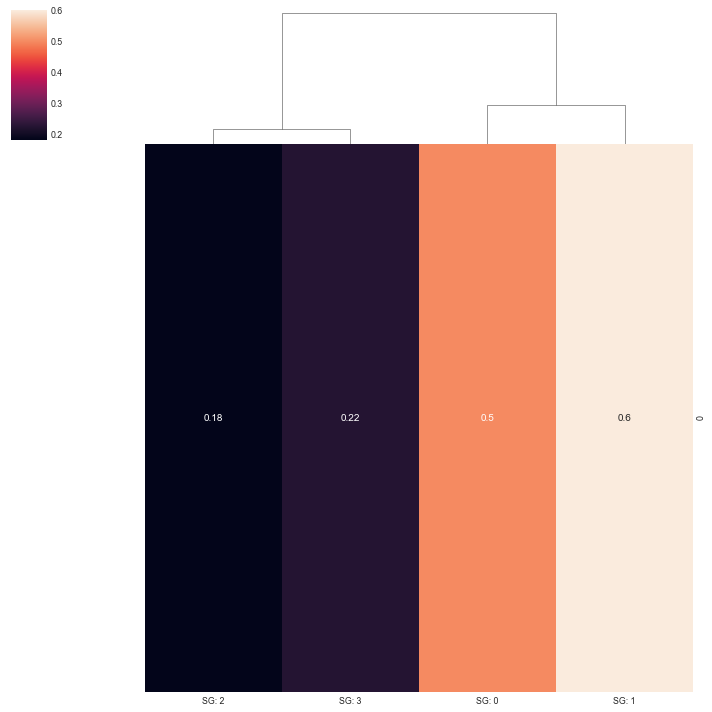

In [78]:
sns.clustermap(cluster_log_rank_p_values_df.T, row_cluster=False, annot=True)

In [79]:
cross_cluster_log_rank_p_values = numpy.ones((len(GOOD_ROI_CLUSTERS), len(GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[r_roi_cc] == 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 15 or r_N < 15:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cross_cluster_log_rank_p_values[l_ind, r_ind] = current_test.p_value
        if cross_cluster_log_rank_p_values[l_ind, r_ind] < .05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_current_df.shape[0]} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_current_df.shape[0]}\n(log-rank p = {round(cross_cluster_log_rank_p_values[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

In [80]:
cross_cluster_log_rank_p_values_df = pandas.DataFrame(
    cross_cluster_log_rank_p_values,
    index=GOOD_ROI_CLUSTERS,
    columns=GOOD_ROI_CLUSTERS,
)
cross_cluster_log_rank_p_values_df.index.name = f'{ROI_COLUMN} Clusters'
cross_cluster_log_rank_p_values_df.columns.name = f'{ROI_COLUMN} Clusters'

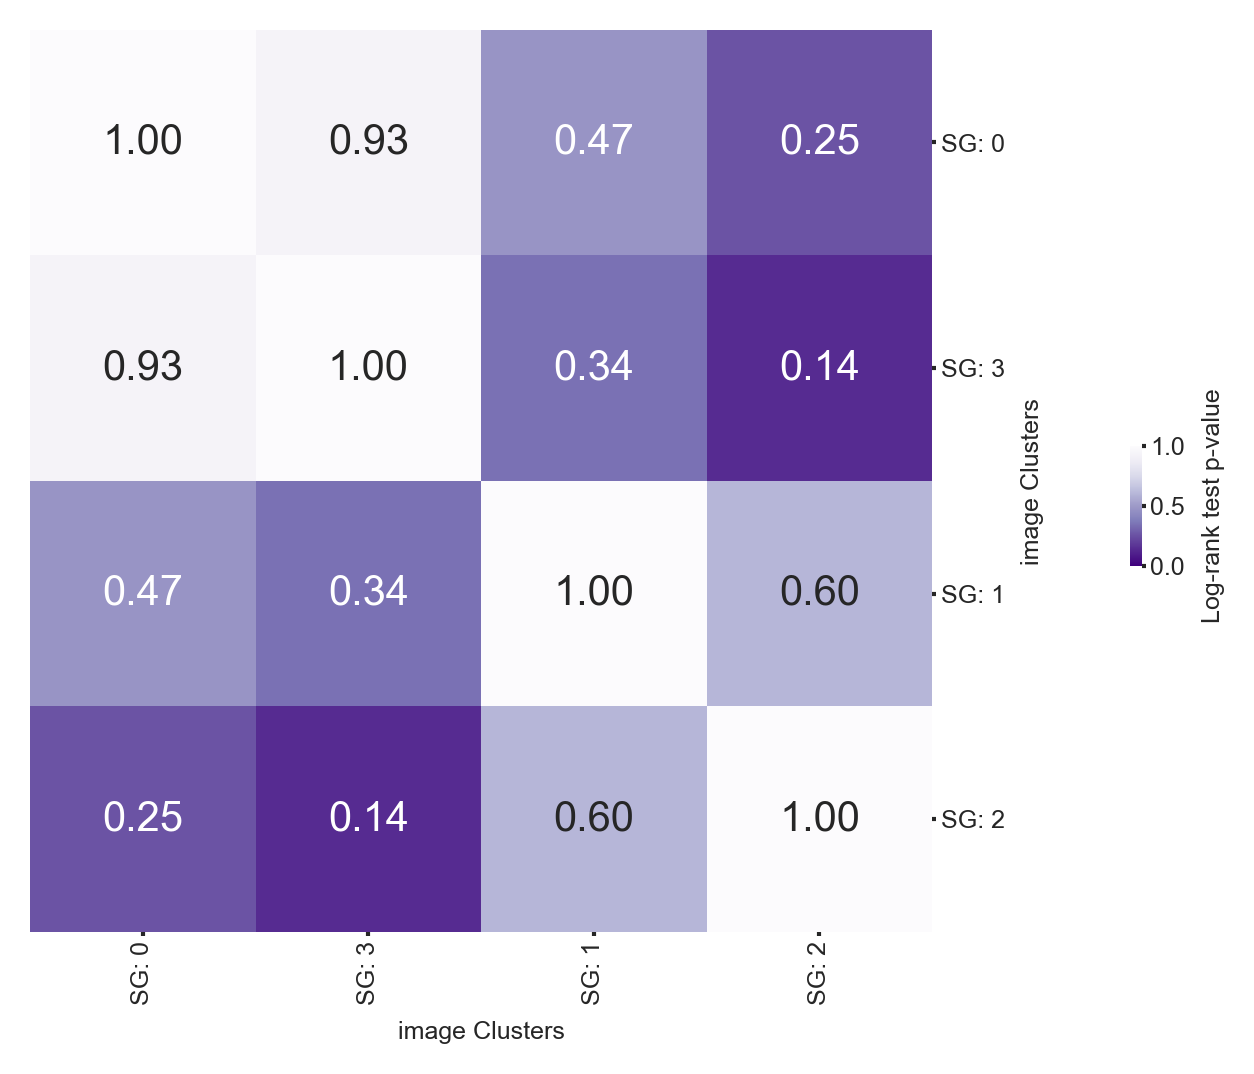

In [81]:
cross_cluster_log_rank_cmap = sns.clustermap(
    cross_cluster_log_rank_p_values_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cross_cluster_log_rank_cmap.ax_cbar.set_visible('False')
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cross_cluster_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cross_cluster_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cross_cluster_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cross_cluster_log_rank_cmap.ax_heatmap.set_yticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cross_cluster_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cross_cluster_log_rank_cmap.ax_heatmap.set_xticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cross_cluster_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cross_cluster_log_rank_cmap.fig.set_size_inches((4, 4))

### Clinical Type vs ROI analysis

In [82]:
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


cluster_vs_ct_log_rank_pvalues = numpy.ones((len(CLINICAL_TYPES), len(GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(CLINICAL_TYPES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_histology'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 15 or r_N < 15:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] < .05:
            plt.figure(figsize=(1.4, 1.4), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(cluster_vs_ct_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            plt.show()

In [83]:
cluster_vs_ct_log_rank_pvalues_df = pandas.DataFrame(
    cluster_vs_ct_log_rank_pvalues,
    columns=GOOD_ROI_CLUSTERS,
    index=CLINICAL_TYPES,
)
cluster_vs_ct_log_rank_pvalues_df.columns.name = f'{ROI_COLUMN} Clusters'
cluster_vs_ct_log_rank_pvalues_df.index.name = f'Clinical Type'

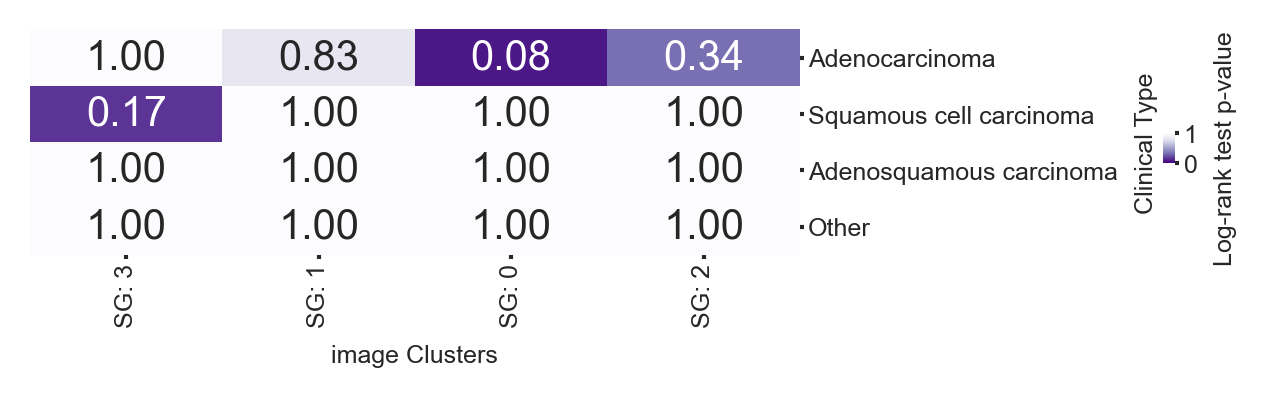

In [84]:
cluster_vs_ct_log_rank_cmap = sns.clustermap(
    cluster_vs_ct_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cluster_vs_ct_log_rank_cmap.ax_cbar.set_visible('False')
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cluster_vs_ct_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cluster_vs_ct_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cluster_vs_ct_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cluster_vs_ct_log_rank_cmap.ax_heatmap.set_yticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cluster_vs_ct_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cluster_vs_ct_log_rank_cmap.ax_heatmap.set_xticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cluster_vs_ct_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cluster_vs_ct_log_rank_cmap.fig.set_size_inches((4, 1))

### Clinical type vs ROI

In [85]:
ct_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(CLINICAL_TYPES)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(CLINICAL_TYPES):
        l_current_df = current_df[current_df['simple_histology'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_histology'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] < .05:
            plt.figure(figsize=(1.4, 1.5), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & {r_roi_cc}, N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & !{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'{l_roi_cc} vs {r_roi_cc} (p={round(ct_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.set_xlabel('timeline', labelpad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            ax.grid(color='white', gapcolor='gray')
            plt.tight_layout()
            plt.show()

In [86]:
ct_vs_cluster_log_rank_pvalues_df = pandas.DataFrame(
    ct_vs_cluster_log_rank_pvalues,
    index=GOOD_ROI_CLUSTERS,
    columns=CLINICAL_TYPES,
)
ct_vs_cluster_log_rank_pvalues_df.index.name = f'{ROI_COLUMN} Clusters'
ct_vs_cluster_log_rank_pvalues_df.columns.name = f'Clinical Type'

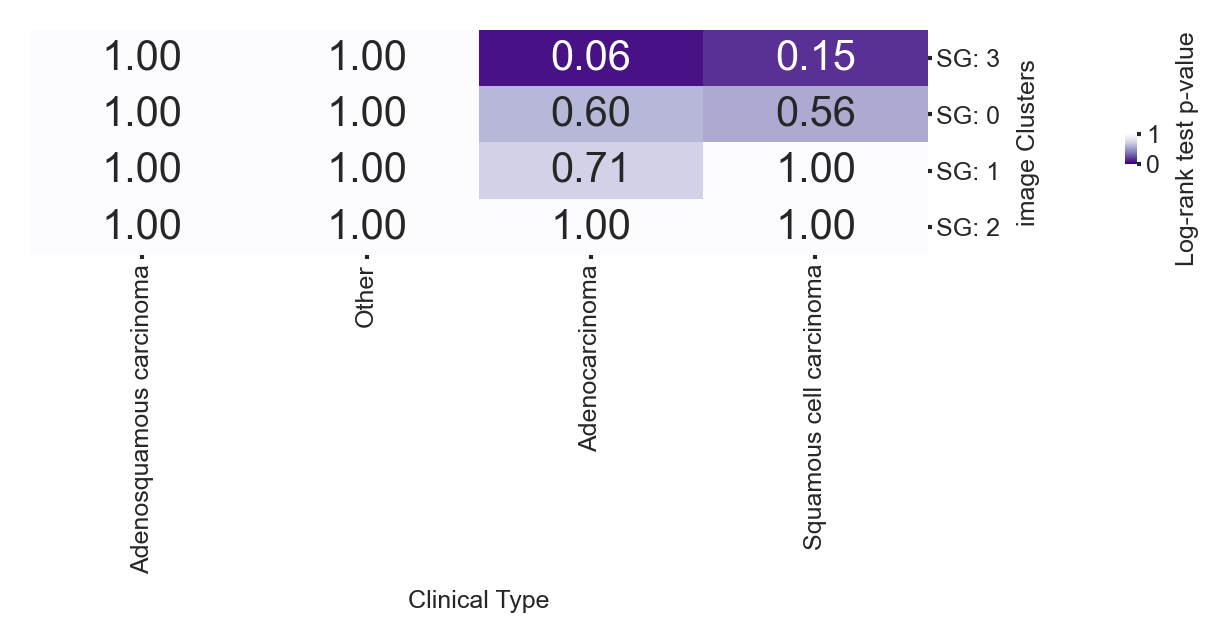

In [87]:
ct_vs_clusterlog_rank_cmap = sns.clustermap(
    ct_vs_cluster_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

ct_vs_clusterlog_rank_cmap.ax_cbar.set_visible('False')
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

ct_vs_clusterlog_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
ct_vs_clusterlog_rank_cmap.ax_row_dendrogram.set_visible(False)
ct_vs_clusterlog_rank_cmap.ax_col_dendrogram.set_visible(False)

ct_vs_clusterlog_rank_cmap.ax_heatmap.set_yticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
ct_vs_clusterlog_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
ct_vs_clusterlog_rank_cmap.ax_heatmap.set_xticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

ct_vs_clusterlog_rank_cmap.fig.set_dpi(PLOTTING_DPI)
ct_vs_clusterlog_rank_cmap.fig.set_size_inches((4, 1))

## Grade vs ROI

In [88]:
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(GRADES)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(GRADES):
        l_current_df = current_df[current_df['simple_stage'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_stage'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            print(l_roi_cc, r_roi_cc, l_N, r_N)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

SG: 0 3 6 29
SG: 0 4 1 34
SG: 1 3 5 33
SG: 1 4 2 36
SG: 2 2 8 35
SG: 2 4 5 38
SG: 3 4 1 55


In [89]:
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GRADES), len(GOOD_ROI_CLUSTERS)))

xticks_font = matplotlib.font_manager.FontProperties(family='Arial')


for l_ind, l_roi_cc in enumerate(GRADES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            print(l_roi_cc, r_roi_cc)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.4, 1.5), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & {r_roi_cc},  N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & !{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'Grade {l_roi_cc} vs {r_roi_cc} (p={round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            #c
            plt.tight_layout()
            plt.show()

2 SG: 2
3 SG: 0
3 SG: 1
4 SG: 0
4 SG: 1
4 SG: 2
4 SG: 3


In [90]:
grade_vs_cluster_log_rank_pvalues

array([[0.2050205 , 0.76854509, 0.28996276, 0.48624834],
       [0.44607638, 0.6703226 , 1.        , 0.46601422],
       [1.        , 1.        , 0.24420617, 0.21212979],
       [1.        , 1.        , 1.        , 1.        ]])

## Marker Cluster analysis for cell types

Now let's analyse the marker expression for cells within certain Cellohood Clusters:

In [91]:
celltypes_display_percentage = defaultdict(lambda: 0.05)
celltypes_display_percentage['Tumor'] = 0.15

In [92]:
celltypes_to_marker_to_show = {
    'B': ['CD40', 'CD20', 'VISTA'],
    'BnT': ['ICOS'],
    'CD4': ['LAG3', 'CD45RO', 'CD45RA'],
    'CD8': ['PD1', 'GrB', 'LAG3', 'CD45RO', 'CD45RA'],
    'plasma': ['CD38'],
    'Tumor': ['ECad', 'PDL1', 'B2M'],
    'All': ['VISTA', 'Ki67', 'Ido1', 'PDL1']
}

In [93]:
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show if ct in celltype_percentages.columns
}

In [94]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

/tmp/ipykernel_1213878/2571668131.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_1213878/2571668131.py:69: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


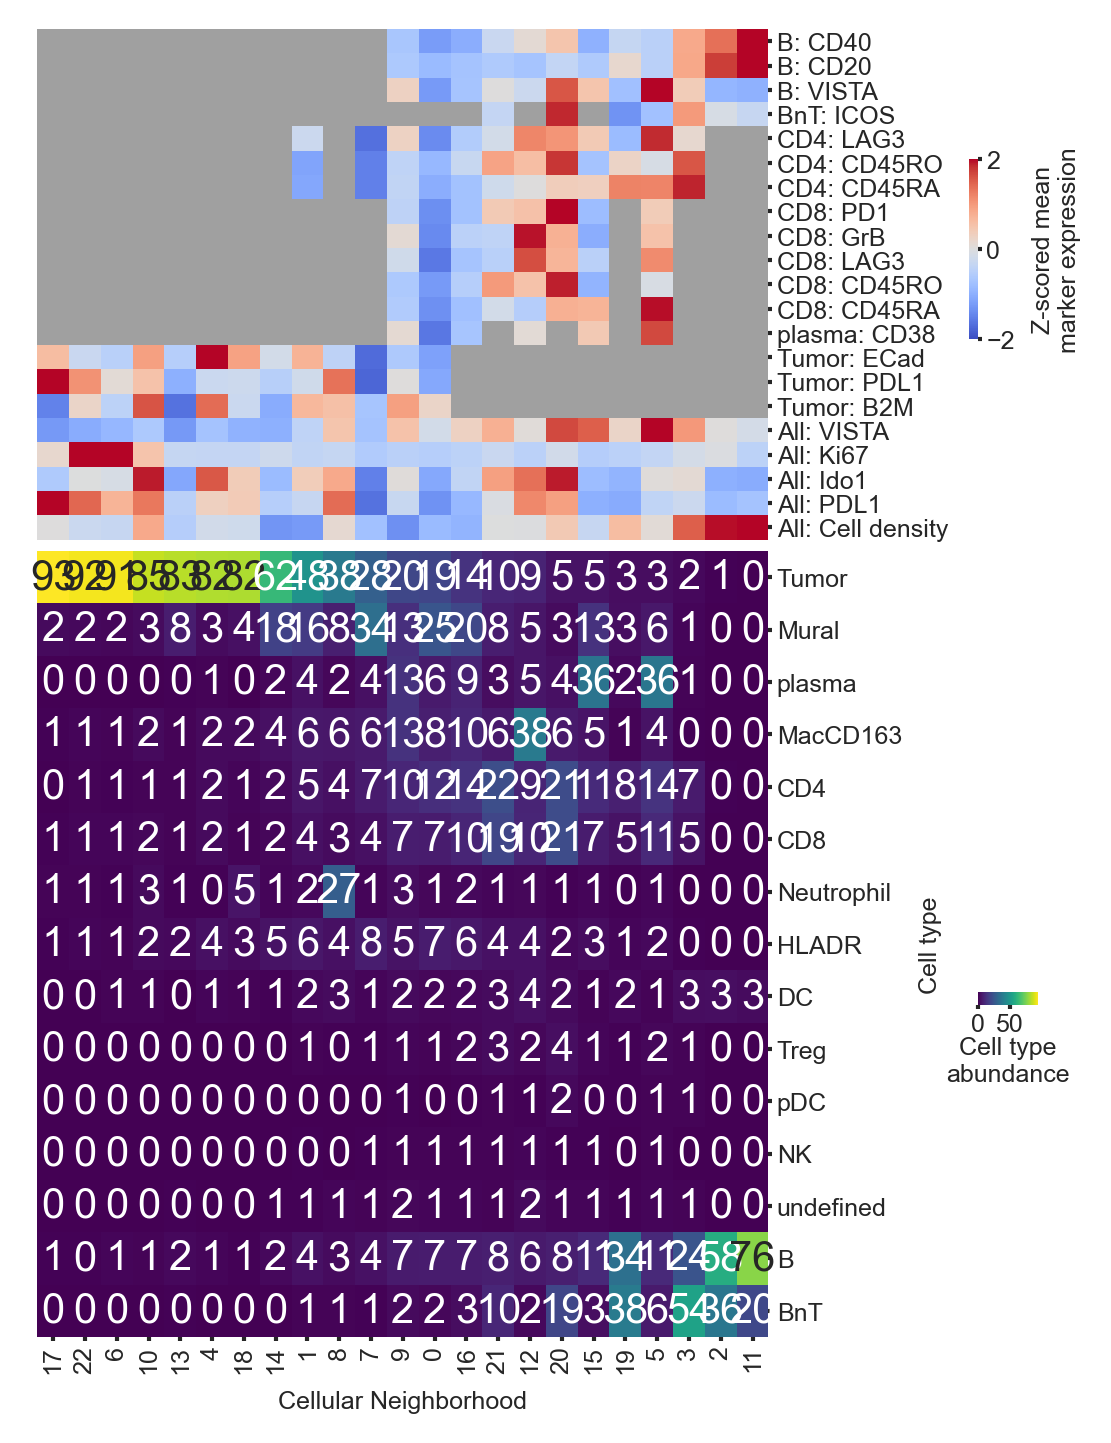

In [95]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-celltype_percentages['Tumor'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[cc_abundance_std_argsort], 
    annot=True,
    col_cluster=False,
    fmt='.0f',
    cmap='viridis',
    figsize=(5, 7),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=cc_abundance_std_argsort,
    #linewidth=0.003
    #annot_kws={"size": 3},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.25, 0.05, .007],
    cbar_kws={'label': 'Cell type\nabundance', 'orientation': 'horizontal'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_cbar.set_xlabel('Cell type\nabundance', labelpad=0, size=6)


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4, 6))
plt.tight_layout()

In [96]:
clustering_df = pandas.DataFrame(
    clusterer.cluster_centers_[GOOD_ROI_CLUSTERS_INDS],
    index=GOOD_ROI_CLUSTERS,
    columns=[col for col in range(CC_NB_OF_CLUSTERS)],
)

In [97]:
CLUSTERS_TO_EXCLUDE = [
    10, 6, 22, 18, 4, 14, 13, 17, 8,  1, 9
]
CLUSTERS_TO_KEEP = [cc_ for cc_ in range(CC_NB_OF_CLUSTERS) if cc_ not in CLUSTERS_TO_EXCLUDE]
CLUSTERS_TO_KEEP = [ 3, 21,  2, 19, 20, 16, 11,  0,  5, 15,  1,  7]#,  9, 14, 12,  4, 13,
        #8, 18, 17, 10,  6, 22]

In [98]:
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=celltype_percentages.iloc[CLUSTERS_TO_KEEP].values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

In [99]:
import ast 


def color_parser(x):
    try:
        return ast.literal_eval(x)
    except:
        return x


full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    full_cc_colors_with_ct[f'{celltype}%'] = [
        ct_sm.to_rgba(x) for x in celltype_percentages[celltype]
    ]
    
READ_COLORS = True
if READ_COLORS:
    full_cc_colors_with_ct = pandas.read_csv('NSCLC-Panel1-SD.75-23.csv')
    full_cc_colors_with_ct.drop('Unnamed: 0', axis=1, inplace=True)
    full_cc_colors_with_ct = full_cc_colors_with_ct.applymap(color_parser)

In [100]:
full_cc_colors_with_ct.index = [i for i in range(full_cc_colors_with_ct.shape[0])]

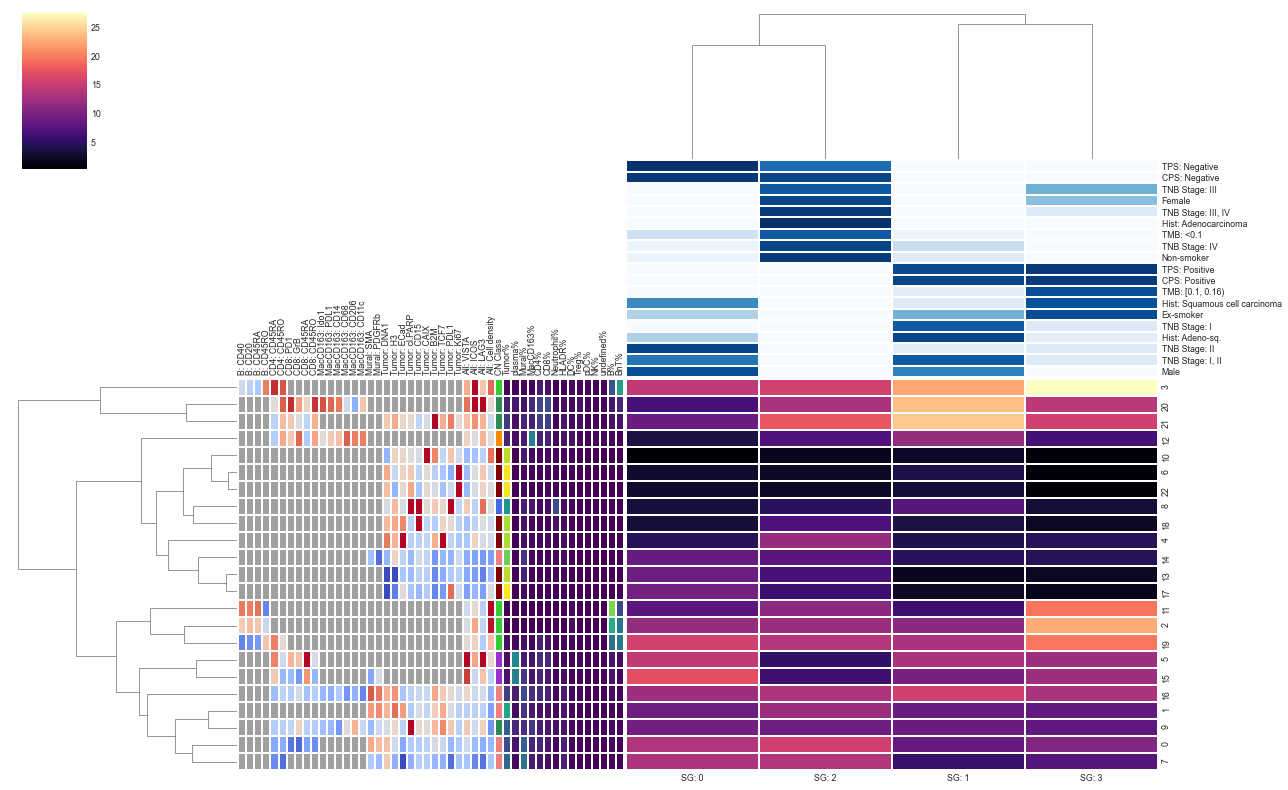

In [101]:
full_cm = sns.clustermap(
    clustering_df.T,  
    cmap='magma',
    col_colors=clinical_colors.T,
    row_colors=full_cc_colors_with_ct,
    figsize=(18, 12),
    colors_ratio=(0.007, 0.015),
    linewidth=0.00395,
    #vmin=-1.5,
    #vmax=1.5,
)

full_cm.ax_row_colors.xaxis.tick_top()
full_cm.ax_row_colors.xaxis.set_tick_params(rotation=90)
#dir(full_cm.ax_row_colors.xaxis)

In [102]:
clinical_colors_with_cluster_color = clinical_colors.copy().T


In [103]:
CELLTYPES_TO_LEAVE = [
    'B',
    'BnT',
    'CD4',
    'CD8',
    'Mural',
    'plasma',
    'All',
    #'Tumor',
]

def is_color_col_to_leave(col, ct_to_leave=None):
    if ct_to_leave is None:
        ct_to_leave = CELLTYPES_TO_LEAVE
    if col.endswith('%'):
        return col[:-1] in ct_to_leave
    if ':' in col:
        return col.split(':')[0] in CELLTYPES_TO_LEAVE
    return True

# BIG-L Fiugre

In [104]:
big_l_full_cc_colors_with_ct = full_cc_colors_with_ct.copy()
big_l_clustering_df = clustering_df.copy()
big_l_clustering_df.columns.name = ''
ct_to_l_selector = numpy.array(
    [is_color_col_to_leave(col) for col in big_l_full_cc_colors_with_ct.columns]
)
big_l_full_cc_colors_with_ct = big_l_full_cc_colors_with_ct.iloc[:, ct_to_l_selector]

In [105]:
def clean_up_big_l_clinical_tick(tick):
    tick_text = tick.get_text()
    return tick_text

In [106]:
big_l_full_cc_colors_with_ct['CN Class'][1]

'#F08080'

In [107]:
clustering_df.to_csv('tls_plda_75_clustering_df.csv')

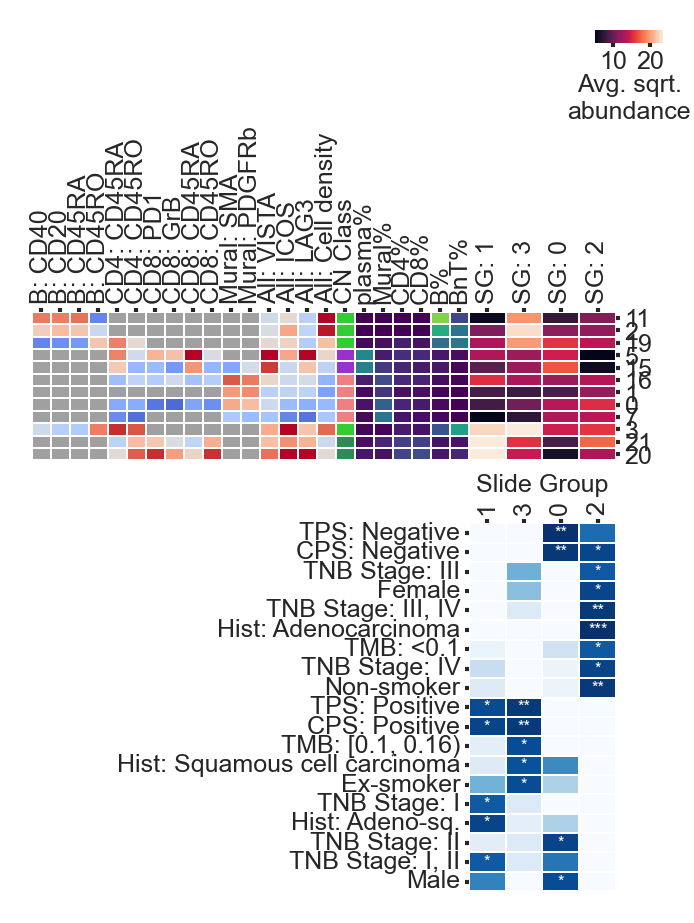

In [108]:
matplotlib.rcParams['font.family'] = 'Arial'

table = big_l_clustering_df[CLUSTERS_TO_KEEP].T

big_l_figure = sns.clustermap(
    table,
    #row_cluster=False,
    figsize=(4.5, 3.5),
    linewidth=0.0035,
    row_colors=big_l_full_cc_colors_with_ct,
    col_colors=clinical_colors_with_cluster_color[list(clinical_colors_with_cluster_color.columns)],
    colors_ratio=(0.026, 0.03),
    xticklabels=True,
    yticklabels=True,
    vmax=numpy.quantile(table.values.flatten(), 0.95),
    cbar_pos=[0.57, 0.7, 0.05, 0.0125],
    cbar_kws={'label': 'Avg. sqrt.\nabundance', 'aspect': 10, 'orientation': 'horizontal'}
)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_col_colors.get_yticklabels()],
    size=6,
)
big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_left()

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.06, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.min[0] - row_box.width, row_box.y0, row_box.width, row_box.height])

big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
#big_l_figure.ax_cbar.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)
#big_l_figure.fig.set_size_inches((9, 6.5))

#big_l_figure.ax_cbar.outline.set_visible(False)
big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xlabel('Avg. sqrt.\nabundance', labelpad=0, size=6)

annot_shape = clinical_cm.data2d.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(clinical_cm.data2d.index)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = clinical_cm.data2d.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + .5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
        
big_l_figure.ax_col_colors.set_xlabel('Slide Group', labelpad=2.2)
big_l_figure.ax_col_colors.xaxis.set_label_position('top')

big_l_figure.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_col_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.set_xticks(
    ticks=[i + 0.5 for i in range(len(big_l_figure.data2d.columns))],
    labels=[int(x.split(':')[1]) for x in big_l_figure.data2d.columns],
    size=6,
)

In [109]:
roi_counts.to_csv('TLS_roi_counts.csv')

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
IMAGES_PATH_PANEL_1 = '/raid/immucan/IMC/NSCLC2/IMC1/unzipped/'
IMAGES_PATH_PANEL_2 = '/raid/immucan/IMC/NSCLC2_PANEL2/unzipped/' 
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
png_to_full_path = defaultdict(list)


for root, dirnames, filenames in os.walk(IMAGES_PATH_PANEL_1):
    for filename in filenames:
        if filename.endswith('.tiff') and 'masks' not in root:
            png_to_full_path[filename].append(os.path.join(root, filename))
            
            
for root, dirnames, filenames in os.walk(IMAGES_PATH_PANEL_2):
    for filename in filenames:
        if filename.endswith('.tiff') and 'masks' not in root:
            png_to_full_path[filename].append(os.path.join(root, filename))
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import pyometiff
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
from pyometiff import OMETIFFReader

reader = OMETIFFReader(fpath=list(png_to_full_path.values())[0][0])

img_array, metadata, xml_metadata = reader.read()
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import numpy as np


def compute_triangle_areas(triangulation):
    """
    Compute areas of all triangles in a matplotlib triangulation
    
    Args:
        triangulation: matplotlib.tri.Triangulation object
        
    Returns:
        numpy array with areas of each triangle
    """
    # Get coordinates and triangles
    x = triangulation.x
    y = triangulation.y
    triangles = triangulation.triangles
    
    # Get vertices for each triangle
    v1 = np.column_stack((x[triangles[:,0]], y[triangles[:,0]]))
    v2 = np.column_stack((x[triangles[:,1]], y[triangles[:,1]]))
    v3 = np.column_stack((x[triangles[:,2]], y[triangles[:,2]]))
    
    # Compute areas using cross product
    # Area = 1/2 * |cross product|
    areas = 0.5 * np.abs(
        (v2[:,0] - v1[:,0]) * (v3[:,1] - v1[:,1]) -
        (v3[:,0] - v1[:,0]) * (v2[:,1] - v1[:,1])
    )
    
    return areas

```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Define the colors and their positions
colors = ['maroon', 'yellow', 'blue']
n_bins = 7  # Number of color gradations

# Create the colormap
custom_cmap = LinearSegmentedColormap.from_list('custom_RYG', colors, N=n_bins)

# Example to visualize the colormap:
plt.figure(figsize=(8, 3))
gradient = np.linspace(0, 1, 256)
gradient = np.vstack((gradient, gradient))
plt.imshow(gradient, aspect='auto', cmap=custom_cmap)
plt.colorbar()
plt.title('Red-Yellow-Green Colormap')
plt.show()
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
cluster_sort = (-celltype_percentages['Tumor'].values).argsort()
CLUSTER_PERM = cluster_sort
CLUSTER_PERM_ARGSORT = numpy.argsort(CLUSTER_PERM)

cell_df['cc_perm'] = cell_df[PREDICTION_CLUSTER_COLUMN].apply(lambda x: CLUSTER_PERM_ARGSORT[x])
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import matplotlib


CLUSTER_TO_ANALYZE = 0
cluster_images = list(set(roi_counts[clusters == CLUSTER_TO_ANALYZE].image))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_1_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('Cellohood\nSD75% - CNs', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=image_df['Cellohood Neighborhood Cluster'].apply(lambda x: big_l_full_cc_colors_with_ct['CN Class'][x]),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('SMA', size=6, pad=0.1)
    ECAD_INDEX = MARKERS.index('SMA')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('VISTA', size=6, pad=0.1)
    KI67_INDEX = MARKERS.index('VISTA')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('ICOS', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('ICOS')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import matplotlib


CLUSTER_TO_ANALYZE = 0
cluster_images = list(set(roi_counts[clusters == CLUSTER_TO_ANALYZE].image))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_1_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('CN Class', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=image_df['Cellohood Neighborhood Cluster'].apply(lambda x: big_l_full_cc_colors_with_ct['CN Class'][x]),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('SMA', size=6, pad=0.1)
    ECAD_INDEX = MARKERS.index('SMA')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('VISTA', size=6, pad=0.1)
    KI67_INDEX = MARKERS.index('VISTA')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('ICOS', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('ICOS')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import matplotlib


CLUSTER_TO_ANALYZE = 1
cluster_images = list(set(roi_counts[clusters == CLUSTER_TO_ANALYZE].image))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_1_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('CN class', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=image_df['Cellohood Neighborhood Cluster'].apply(lambda x: big_l_full_cc_colors_with_ct['CN Class'][x]),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('CD45RA', size=6, pad=0.1)
    ECAD_INDEX = MARKERS.index('CD45RA')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
        vmax=2,
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('CD45RO', size=6, pad=0.1)
    KI67_INDEX = MARKERS.index('CD45RO')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
        vmax=2.5,
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('CD40', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('CD40')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
        vmax=1.7,
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import matplotlib


CLUSTER_TO_ANALYZE = 3
cluster_images = list(set(roi_counts[clusters == CLUSTER_TO_ANALYZE].image))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_1_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('CN class', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=image_df['Cellohood Neighborhood Cluster'].apply(lambda x: big_l_full_cc_colors_with_ct['CN Class'][x]),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('CD45RA', size=6, pad=0.1)
    ECAD_INDEX = MARKERS.index('CD45RA')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('CD45RO', size=6, pad=0.1)
    KI67_INDEX = MARKERS.index('CD45RO')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('CD40', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('CD40')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()
```

**[Excluded from execution]** This cell was part of a per-image example-gallery visualization block (raw TIFF loading + per-cluster marker-channel panels) that fails on a fresh run (KeyError: 'Cellohood Neighborhood Cluster' missing from image_df -- same category of out-of-order-editing / orphaned-dependency issue seen in the P1 TUMOR notebook's equivalent block). It is illustrative only, not used by any downstream clinical or statistical analysis, so it was excluded rather than patched piece by piece. Original source preserved below for reference.

```python
import matplotlib


CLUSTER_TO_ANALYZE = 2
cluster_images = list(set(roi_counts[clusters == CLUSTER_TO_ANALYZE].image))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_1_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('CN Class', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=image_df['Cellohood Neighborhood Cluster'].apply(lambda x: big_l_full_cc_colors_with_ct['CN Class'][x]),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('SMA', size=6, pad=0.1)
    ECAD_INDEX = MARKERS.index('SMA')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('VISTA', size=6, pad=0.1)
    KI67_INDEX = MARKERS.index('VISTA')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('ICOS', size=6, pad=0.1)
    CD3_INDEX = MARKERS.index('ICOS')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()
```

In [110]:
roi_cluster_with_clinical

,immucan_id,SG: 0,SG: 1,SG: 2,SG: 3,Unnamed: 0,patient_id,age_at_registration,disease,date_of_diagnosis,...,PIK3CA,RET,NTRK1,ERBB2,MET,NRG1,FGFR1,BRAF,ROS1,is_squamous
0,LUNG-NSCLC2-0552,False,False,True,False,0,1,60,Lung cancer,2014-11-04,...,False,False,False,False,False,False,False,False,False,False
1,LUNG-NSCLC2-0553,True,False,False,False,1,2,75,Lung cancer,2014-12-11,...,False,False,False,False,False,False,False,False,False,False
2,LUNG-NSCLC2-0554,True,False,False,False,2,3,66,Lung cancer,2015-01-20,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,LUNG-NSCLC2-0555,False,True,False,False,3,4,64,Lung cancer,2012-11-09,...,False,False,False,False,False,False,False,False,False,False
4,LUNG-NSCLC2-0556,False,False,True,False,4,6,68,Lung cancer,2014-11-17,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167,LUNG-NSCLC2-0739,False,False,False,True,187,595,76,Lung cancer,2017-09-05,...,False,False,False,False,False,False,False,False,False,False
168,LUNG-NSCLC2-0740,False,False,False,True,188,596,61,Lung cancer,2017-10-18,...,False,False,False,False,False,False,False,False,False,False
169,LUNG-NSCLC2-0741,False,False,False,True,189,598,59,Lung cancer,2017-11-23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
170,LUNG-NSCLC2-0742,True,False,False,False,190,599,80,Lung cancer,2017-09-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
